In [2]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "pkg_modelling").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from pkg_modelling.modelling_utils import temporal_train_validation_split, build_preprocessor, build_logistic_pipeline, evaluate_probability_model


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [65]:
from pkg_modelling.plot_roc import (
    plot_roc_curves,
    plot_precision_recall_curves,
    plot_calibration_curves
)

In [91]:
import shap

In [29]:
import matplotlib.pyplot as plt

from pkg_modelling.plot_roc import plot_validation_curves

In [43]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

In [45]:
import warnings

warnings.filterwarnings("ignore")

In [6]:
train = pd.read_csv("../data/train_feature_engineered_v1.csv", parse_dates=["OBS_DATE"])

test = pd.read_csv("../data/test_feature_engineered_v1.csv", parse_dates=["OBS_DATE"])

# Train/Validation split

In [7]:
development_df, validation_df, validation_start_date = (
    temporal_train_validation_split(
        dataframe=train,
        date_column="OBS_DATE",
        validation_fraction=0.20
    )
)

print(
    "Validation begins:",
    validation_start_date.date()
)

Validation begins: 2014-07-16


In [8]:
split_summary = pd.DataFrame({
    "rows": [
        len(development_df),
        len(validation_df)
    ],
    "defaults": [
        development_df["target_var"].sum(),
        validation_df["target_var"].sum()
    ],
    "default_rate": [
        development_df["target_var"].mean(),
        validation_df["target_var"].mean()
    ],
    "start_date": [
        development_df["OBS_DATE"].min(),
        validation_df["OBS_DATE"].min()
    ],
    "end_date": [
        development_df["OBS_DATE"].max(),
        validation_df["OBS_DATE"].max()
    ]
}, index=["development", "validation"])

split_summary

,rows,defaults,default_rate,start_date,end_date
development,5268,787,0.149393,2008-01-02,2014-07-15
validation,1319,222,0.168309,2014-07-16,2016-03-16


In [9]:
assert len(development_df) + len(validation_df) == len(train)

assert (
    development_df["OBS_DATE"].max()
    < validation_df["OBS_DATE"].min()
)

assert set(development_df["target_var"].unique()).issubset({0, 1})
assert set(validation_df["target_var"].unique()).issubset({0, 1})

assert development_df["target_var"].nunique() == 2
assert validation_df["target_var"].nunique() == 2

print("Temporal split checks passed.")

Temporal split checks passed.


# Combination Feature Sets

In [10]:
install_feature_sets = {
    "raw": ["install_to_inc"],
    "raw_with_missing": [
        "install_to_inc",
        "install_to_inc_missing"
    ],
    "log": ["install_to_inc_log"],
    "log_with_missing_indicator": [
        "install_to_inc_log",
        "install_to_inc_missing"
    ]
}

In [11]:
income_feature_sets = {
    "continuous": [
        "income"
    ],
    "continuous_with_missing": [
        "income",
        "income_missing"
    ],
    "brackets": [
        "income_bracket"
    ],
    "continuous_plus_brackets": [
        "income",
        "income_bracket"
    ],
    "spline": [
        "income"
    ]
}

In [12]:
loan_amount_feature_sets = {
    "continuous": [
        "loan_amount"
    ],
    "continuous_with_missing": [
        "loan_amount",
        "loan_amount_missing"
    ],
    "brackets": [
        "loan_amount_bracket"
    ],
    "continuous_plus_brackets": [
        "loan_amount",
        "loan_amount_bracket"
    ],
    "spline": [
        "loan_amount"
    ]
}

In [13]:
term_length_feature_sets = {
    "continuous": [
        "term_length"
    ],
    "continuous_with_missing": [
        "term_length",
        "term_length_missing"
    ],
    "brackets": [
        "term_length_bracket"
    ],
    "continuous_plus_brackets": [
        "term_length",
        "term_length_bracket"
    ],
    "spline": [
        "term_length"
    ]
}

In [14]:
schufa_feature_sets = {
    "continuous": [
        "schufa"
    ],
    "continuous_with_missing": [
        "schufa",
        "schufa_missing"
    ],
    "log": [
        "schufa_log"
    ],
    "log_with_missing": [
        "schufa_log",
        "schufa_missing"
    ],
    "brackets": [
        "schufa_bracket"
    ],
    "continuous_plus_brackets": [
        "schufa",
        "schufa_bracket"
    ],
    "log_plus_brackets": [
        "schufa_log",
        "schufa_bracket"
    ],
    "spline": [
        "schufa"
    ]
}

In [15]:
feature_set_registry = {
    "install_to_inc": install_feature_sets,
    "income": income_feature_sets,
    "loan_amount": loan_amount_feature_sets,
    "term_length": term_length_feature_sets,
    "schufa": schufa_feature_sets
}

# Basic Model

## Set-up

In [16]:
baseline_feature_choices = {
    "install_to_inc": "raw_with_missing",
    "income": "continuous_with_missing",
    "loan_amount": "continuous_with_missing",
    "term_length": "continuous_with_missing",
    "schufa": "continuous_with_missing"
}

In [17]:
selected_numerical_features = []

for feature_name, representation in baseline_feature_choices.items():
    selected_numerical_features.extend(
        feature_set_registry[feature_name][representation]
    )

# Preserve order while removing any duplicates
selected_numerical_features = list(
    dict.fromkeys(selected_numerical_features)
)

selected_numerical_features

['install_to_inc',
 'install_to_inc_missing',
 'income',
 'income_missing',
 'loan_amount',
 'loan_amount_missing',
 'term_length',
 'term_length_missing',
 'schufa',
 'schufa_missing']

In [18]:
continuous_features = [
    feature
    for feature in selected_numerical_features
    if not feature.endswith("_missing")
]

missing_indicator_features = [
    feature
    for feature in selected_numerical_features
    if feature.endswith("_missing")
]

categorical_dummy_features = [
    column
    for column in train.columns
    if column.startswith((
        "occup_",
        "marital_",
        "num_applic_"
    ))
]

binary_features = (
    missing_indicator_features
    + categorical_dummy_features
)

baseline_features = (
    continuous_features
    + binary_features
)

baseline_features = list(dict.fromkeys(baseline_features))

In [19]:
print("Selected representations:")
display(pd.Series(baseline_feature_choices, name="representation"))

print("\nContinuous features:")
print(continuous_features)

print("\nMissing indicators:")
print(missing_indicator_features)

print("\nExisting categorical dummies:")
print(categorical_dummy_features)

print("\nTotal baseline features:", len(baseline_features))

Selected representations:


install_to_inc           raw_with_missing
income            continuous_with_missing
loan_amount       continuous_with_missing
term_length       continuous_with_missing
schufa            continuous_with_missing
Name: representation, dtype: str


Continuous features:
['install_to_inc', 'income', 'loan_amount', 'term_length', 'schufa']

Missing indicators:
['install_to_inc_missing', 'income_missing', 'loan_amount_missing', 'term_length_missing', 'schufa_missing']

Existing categorical dummies:
['occup_code_1', 'occup_code_2', 'occup_code_3', 'occup_Employee', 'occup_Student', 'occup_Worker', 'occup_nan', 'marital_Divorced', 'marital_Living together', 'marital_Married', 'marital_Separated', 'marital_Single', 'marital_nan', 'num_applic_1', 'num_applic_2', 'num_applic_nan']

Total baseline features: 26


In [20]:
missing_columns = [
    column
    for column in baseline_features
    if column not in train.columns
]

non_numeric_columns = (
    train[baseline_features]
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)

print("Missing columns:", missing_columns)
print("Non-numeric columns:", non_numeric_columns)

assert not missing_columns
assert not non_numeric_columns

Missing columns: []
Non-numeric columns: []


In [21]:
X_development = development_df[baseline_features]
y_development = development_df["target_var"].astype(int)

X_validation = validation_df[baseline_features]
y_validation = validation_df["target_var"].astype(int)

print("Development X:", X_development.shape)
print("Validation X: ", X_validation.shape)

Development X: (5268, 26)
Validation X:  (1319, 26)


## Pipeline

In [22]:
baseline_preprocessor = build_preprocessor(
    continuous_features=continuous_features,
    binary_features=binary_features
)

logistic_baseline = build_logistic_pipeline(
    preprocessor=baseline_preprocessor,
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    class_weight=None,
    random_state=42
)

logistic_baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

### benchmarks (dummy and SCHUFA)

In [24]:
dummy_baseline = Pipeline([
    (
        "preprocessing",
        clone(baseline_preprocessor)
    ),
    (
        "classifier",
        DummyClassifier(strategy="prior")
    )
])

In [25]:
schufa_preprocessor = build_preprocessor(
    continuous_features=["schufa"],
    binary_features=[]
)

schufa_benchmark = build_logistic_pipeline(
    preprocessor=schufa_preprocessor,
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    class_weight=None,
    random_state=42
)

## Model and benchmarks Fitting

In [26]:
dummy_baseline.fit(
    X_development,
    y_development
)

schufa_benchmark.fit(
    development_df[["schufa"]],
    y_development
)

logistic_baseline.fit(
    X_development,
    y_development
)

/Users/valery/VS Code Repos/OliverWymanTakeHomeTask/python3_11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/valery/VS Code Repos/OliverWymanTakeHomeTask/python3_11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf inst

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['install_to_inc','income','loan_amount',...,'num_applic_1','num_applic_2', 'num_applic_nan']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that f

## Temporal Validation

In [27]:
baseline_results = pd.DataFrame([
    evaluate_probability_model(
        model_name="Dummy prior",
        model=dummy_baseline,
        X=X_validation,
        y=y_validation
    ),
    evaluate_probability_model(
        model_name="SCHUFA-only logistic",
        model=schufa_benchmark,
        X=validation_df[["schufa"]],
        y=y_validation
    ),
    evaluate_probability_model(
        model_name="Basic — raw continuous",
        model=logistic_baseline,
        X=X_validation,
        y=y_validation
    )
]).set_index("model")

baseline_results.round(4)

,roc_auc,pr_auc,log_loss,brier_score,mean_predicted_default,actual_default_rate
model,,,,,,
Dummy prior,0.5000,0.1683,0.4546,0.1403,0.1494,0.1683
SCHUFA-only logistic,0.7880,0.3736,0.3752,0.1201,0.1526,0.1683
Basic — raw continuous,0.9277,0.7085,0.2456,0.0785,0.1584,0.1683


In [28]:
from sklearn.metrics import roc_auc_score

observed_schufa = validation_df["schufa"].notna()

schufa_direct_auc = roc_auc_score(
    validation_df.loc[observed_schufa, "target_var"],
    -validation_df.loc[observed_schufa, "schufa"]
)

print(
    "Direct SCHUFA validation ROC-AUC:",
    round(schufa_direct_auc, 4)
)

Direct SCHUFA validation ROC-AUC: 0.793


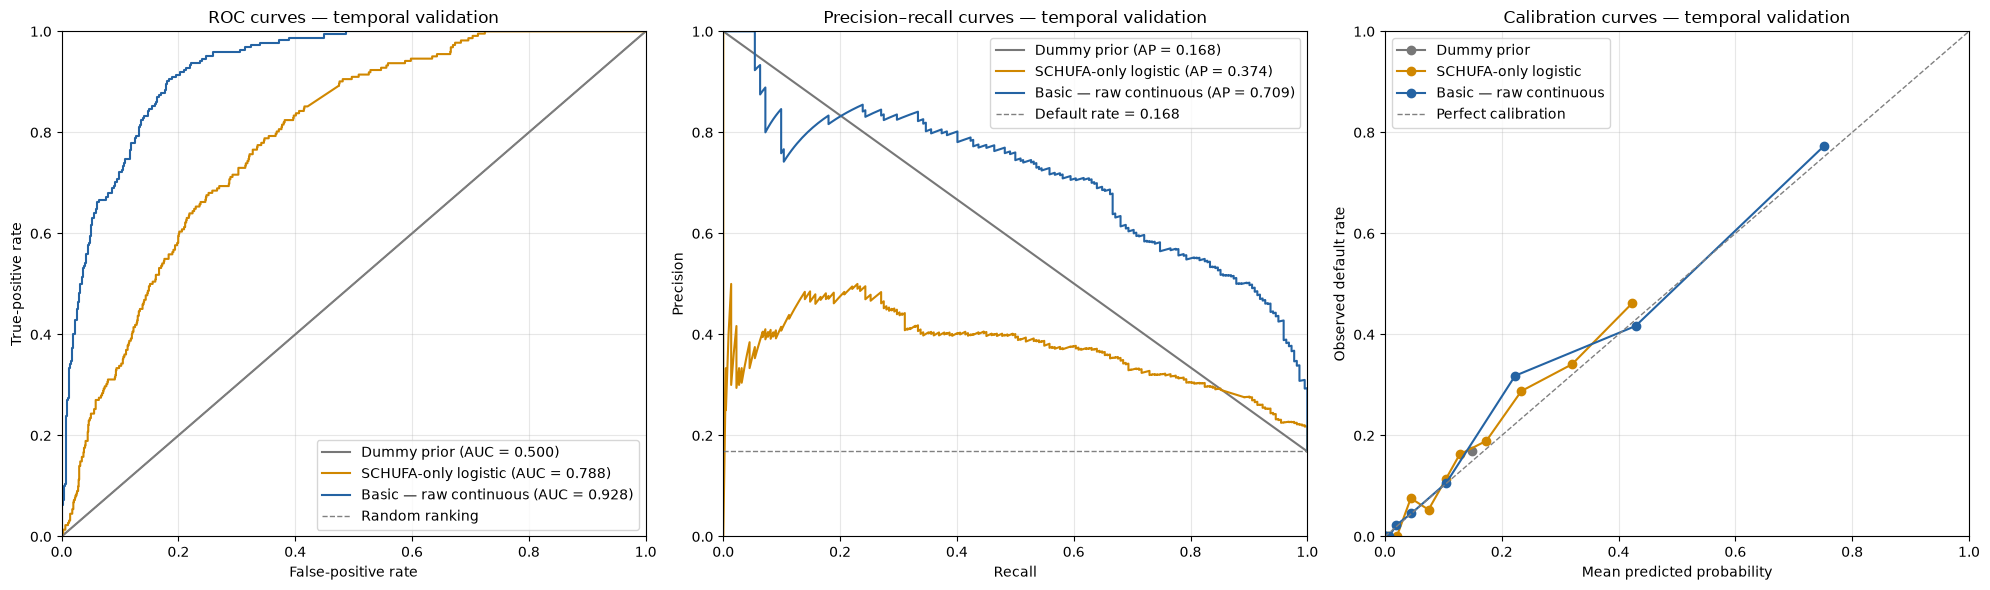

In [31]:
validation_predictions = {
    "Dummy prior": dummy_baseline.predict_proba(
        X_validation
    )[:, 1],

    "SCHUFA-only logistic": schufa_benchmark.predict_proba(
        validation_df[["schufa"]]
    )[:, 1],

    "Basic — raw continuous": logistic_baseline.predict_proba(
        X_validation
    )[:, 1]
}

model_styles = {
    "Dummy prior": {
        "color": "#777777",
        "linestyle": "-"
    },
    "SCHUFA-only logistic": {
        "color": "#D08700",
        "linestyle": "-"
    },
    "Basic — raw continuous": {
        "color": "#2463A3",
        "linestyle": "-"
    }
}

figure, axes = plot_validation_curves(
    y_true=y_validation,
    predictions=validation_predictions,
    model_styles=model_styles,
    figure_size=(20, 6),
    title_suffix="temporal validation",
    calibration_bins=10,
    calibration_strategy="quantile"
)

plt.show()

# Comparison models

## define feature sets for all model trials

In [32]:
train.columns

Index(['income', 'loan_amount', 'term_length', 'install_to_inc', 'schufa',
       'OBS_DATE', 'target_var', 'occup_code_1', 'occup_code_2',
       'occup_code_3', 'occup_Employee', 'occup_Student', 'occup_Worker',
       'occup_nan', 'marital_Divorced', 'marital_Living together',
       'marital_Married', 'marital_Separated', 'marital_Single', 'marital_nan',
       'num_applic_1', 'num_applic_2', 'num_applic_nan',
       'install_to_inc_missing', 'install_to_inc_log', 'income_missing',
       'income_bracket', 'loan_amount_missing', 'loan_amount_bracket',
       'term_length_missing', 'term_length_bracket', 'schufa_missing',
       'schufa_log', 'schufa_bracket'],
      dtype='str')

In [34]:
# Features shared by every model
categorical_dummy_features = [
    column
    for column in train.columns
    if column.startswith((
        "occup_",
        "marital_",
        "num_applic_"
    ))
]

raw_numerical_features = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "schufa"
]

log_numerical_features = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc_log",
    "schufa_log"
]

missing_indicator_features = [
    "income_missing",
    "loan_amount_missing",
    "term_length_missing",
    "install_to_inc_missing",
    "schufa_missing"
]

bracket_features = [
    "income_bracket",
    "loan_amount_bracket",
    "term_length_bracket",
    "schufa_bracket"
]


comparison_feature_sets = {
    # 1. Raw numerical values; nulls will be median-imputed
    "Raw without missing flags": {
        "continuous_features": raw_numerical_features,
        "binary_features": [
            *categorical_dummy_features
        ],
        "categorical_features": [],
        "spline_features": []
    },

    # 2. Raw numerical values plus explicit original-null indicators
    "Raw with missing flags": {
        "continuous_features": raw_numerical_features,
        "binary_features": [
            *categorical_dummy_features,
            *missing_indicator_features
        ],
        "categorical_features": [],
        "spline_features": []
    },

    # 3. Logged ratio and SCHUFA; no missingness indicators
    "Logged without missing flags": {
        "continuous_features": log_numerical_features,
        "binary_features": [
            *categorical_dummy_features
        ],
        "categorical_features": [],
        "spline_features": []
    },

    # 4. Logged ratio and SCHUFA plus missingness indicators
    "Logged with missing flags": {
        "continuous_features": log_numerical_features,
        "binary_features": [
            *categorical_dummy_features,
            *missing_indicator_features
        ],
        "categorical_features": [],
        "spline_features": []
    },

    # 5. Custom brackets for four variables.
    # install_to_inc has no bracket, so retain its logged representation.
    "Brackets": {
        "continuous_features": [
            "install_to_inc_log"
        ],
        "binary_features": [
            *categorical_dummy_features,
            "install_to_inc_missing"
        ],
        "categorical_features": bracket_features,
        "spline_features": []
    },

    # 6. Best continuous representations plus custom brackets.
    # The bracket Missing categories preserve missingness for the
    # four bracketed variables, so only the ratio needs a separate flag.
    "Continuous plus brackets": {
        "continuous_features": log_numerical_features,
        "binary_features": [
            *categorical_dummy_features,
            "install_to_inc_missing"
        ],
        "categorical_features": bracket_features,
        "spline_features": []
    },

    # 7. Smooth nonlinear representations of all five raw variables
    "Splines": {
        "continuous_features": [],
        "binary_features": [
            *categorical_dummy_features,
            *missing_indicator_features
        ],
        "categorical_features": [],
        "spline_features": raw_numerical_features
    }
}

In [35]:
for model_name, feature_set in comparison_feature_sets.items():
    feature_groups = [
        feature_set["continuous_features"],
        feature_set["binary_features"],
        feature_set["categorical_features"],
        feature_set["spline_features"]
    ]

    all_model_features = [
        feature
        for group in feature_groups
        for feature in group
    ]

    missing_columns = [
        feature
        for feature in all_model_features
        if feature not in train.columns
    ]

    duplicated_columns = (
        pd.Series(all_model_features)
        .value_counts()
        .loc[lambda counts: counts > 1]
        .index
        .tolist()
    )

    assert not missing_columns, (
        f"{model_name} has missing columns: {missing_columns}"
    )

    assert not duplicated_columns, (
        f"{model_name} assigns columns to multiple branches: "
        f"{duplicated_columns}"
    )

In [36]:
feature_set_summary = pd.DataFrame({
    model_name: {
        "continuous": len(feature_set["continuous_features"]),
        "binary": len(feature_set["binary_features"]),
        "categorical_brackets": len(
            feature_set["categorical_features"]
        ),
        "spline_inputs": len(feature_set["spline_features"]),
        "total_input_columns": sum(
            len(features)
            for features in feature_set.values()
        )
    }
    for model_name, feature_set in comparison_feature_sets.items()
}).T

feature_set_summary

,continuous,binary,categorical_brackets,spline_inputs,total_input_columns
Raw without missing flags,5,16,0,0,21
Raw with missing flags,5,21,0,0,26
Logged without missing flags,5,16,0,0,21
Logged with missing flags,5,21,0,0,26
Brackets,1,17,4,0,22
Continuous plus brackets,5,17,4,0,26
Splines,0,21,0,5,26


## Fit models

In [46]:
# Use the same complete input frames for every experiment.
# Each pipeline selects only the columns specified in its configuration.
X_development_all = development_df.drop(
    columns=["target_var", "OBS_DATE"],
    errors="ignore"
)

X_validation_all = validation_df.drop(
    columns=["target_var", "OBS_DATE"],
    errors="ignore"
)

comparison_models = {}
comparison_predictions = {}
comparison_result_records = []

for model_name, feature_set in comparison_feature_sets.items():
    preprocessor = build_preprocessor(
        continuous_features=feature_set["continuous_features"],
        binary_features=feature_set["binary_features"],
        categorical_features=feature_set["categorical_features"],
        spline_features=feature_set["spline_features"],
        spline_n_knots=4,
        spline_degree=2
    )

    model = build_logistic_pipeline(
        preprocessor=preprocessor,
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        class_weight=None,
        random_state=42
    )

    model.fit(
        X_development_all,
        y_development
    )

    probabilities = model.predict_proba(
        X_validation_all
    )[:, 1]

    result = evaluate_probability_model(
        model_name=model_name,
        model=model,
        X=X_validation_all,
        y=y_validation
    )

    # Record the number of columns after one-hot/spline transformation
    transformed_feature_count = (
        model
        .named_steps["preprocessing"]
        .transform(X_development_all.iloc[:1])
        .shape[1]
    )

    classifier_iterations = int(
        model
        .named_steps["classifier"]
        .n_iter_
        .max()
    )

    result["transformed_features"] = transformed_feature_count
    result["iterations"] = classifier_iterations

    comparison_models[model_name] = model
    comparison_predictions[model_name] = probabilities
    comparison_result_records.append(result)

    print(
        f"Fitted: {model_name} "
        f"({transformed_feature_count} transformed features)"
    )

Fitted: Raw without missing flags (21 transformed features)
Fitted: Raw with missing flags (26 transformed features)
Fitted: Logged without missing flags (21 transformed features)
Fitted: Logged with missing flags (26 transformed features)
Fitted: Brackets (41 transformed features)
Fitted: Continuous plus brackets (45 transformed features)
Fitted: Splines (41 transformed features)


In [47]:
comparison_results = (
    pd.DataFrame(comparison_result_records)
    .set_index("model")
)

comparison_results.round(4)

,roc_auc,pr_auc,log_loss,brier_score,mean_predicted_default,actual_default_rate,transformed_features,iterations
model,,,,,,,,
Raw without missing flags,0.9296,0.7161,0.2434,0.0777,0.1588,0.1683,21,41
Raw with missing flags,0.9277,0.7085,0.2456,0.0785,0.1584,0.1683,26,44
Logged without missing flags,0.9296,0.7170,0.2436,0.0776,0.1585,0.1683,21,43
Logged with missing flags,0.9278,0.7096,0.2462,0.0784,0.1579,0.1683,26,44
Brackets,0.9253,0.7053,0.2495,0.0797,0.1588,0.1683,41,43
Continuous plus brackets,0.9273,0.7044,0.2466,0.0791,0.1586,0.1683,45,54
Splines,0.9258,0.7042,0.2483,0.0794,0.1585,0.1683,41,83


In [48]:
benchmark_results = pd.DataFrame([
    evaluate_probability_model(
        model_name="Dummy prior",
        model=dummy_baseline,
        X=X_validation,
        y=y_validation
    ),
    evaluate_probability_model(
        model_name="SCHUFA-only logistic",
        model=schufa_benchmark,
        X=validation_df[["schufa"]],
        y=y_validation
    )
]).set_index("model")

benchmark_results.round(4)

,roc_auc,pr_auc,log_loss,brier_score,mean_predicted_default,actual_default_rate
model,,,,,,
Dummy prior,0.500,0.1683,0.4546,0.1403,0.1494,0.1683
SCHUFA-only logistic,0.788,0.3736,0.3752,0.1201,0.1526,0.1683


In [49]:
all_validation_results = pd.concat([
    benchmark_results,
    comparison_results
])

all_validation_results.round(4)

,roc_auc,pr_auc,log_loss,brier_score,mean_predicted_default,actual_default_rate,transformed_features,iterations
model,,,,,,,,
Dummy prior,0.5000,0.1683,0.4546,0.1403,0.1494,0.1683,NaN,NaN
SCHUFA-only logistic,0.7880,0.3736,0.3752,0.1201,0.1526,0.1683,NaN,NaN
Raw without missing flags,0.9296,0.7161,0.2434,0.0777,0.1588,0.1683,21.0,41.0
Raw with missing flags,0.9277,0.7085,0.2456,0.0785,0.1584,0.1683,26.0,44.0
Logged without missing flags,0.9296,0.7170,0.2436,0.0776,0.1585,0.1683,21.0,43.0
Logged with missing flags,0.9278,0.7096,0.2462,0.0784,0.1579,0.1683,26.0,44.0
Brackets,0.9253,0.7053,0.2495,0.0797,0.1588,0.1683,41.0,43.0
Continuous plus brackets,0.9273,0.7044,0.2466,0.0791,0.1586,0.1683,45.0,54.0
Splines,0.9258,0.7042,0.2483,0.0794,0.1585,0.1683,41.0,83.0


## Params tuning

### temporal-folds

In [50]:
development_dates = pd.to_datetime(
    development_df["OBS_DATE"]
)

unique_development_dates = (
    development_dates
    .drop_duplicates()
    .sort_values()
    .to_numpy()
)

date_splitter = TimeSeriesSplit(
    n_splits=4
)

temporal_cv_splits = []
cv_fold_records = []

for fold_number, (
    training_date_positions,
    validation_date_positions
) in enumerate(
    date_splitter.split(unique_development_dates),
    start=1
):
    training_dates = unique_development_dates[
        training_date_positions
    ]

    fold_validation_dates = unique_development_dates[
        validation_date_positions
    ]

    training_indices = np.flatnonzero(
        development_dates.isin(training_dates).to_numpy()
    )

    fold_validation_indices = np.flatnonzero(
        development_dates
        .isin(fold_validation_dates)
        .to_numpy()
    )

    assert (
        development_dates.iloc[training_indices].max()
        <
        development_dates.iloc[fold_validation_indices].min()
    )

    temporal_cv_splits.append(
        (
            training_indices,
            fold_validation_indices
        )
    )

    cv_fold_records.append({
        "fold": fold_number,
        "training_rows": len(training_indices),
        "validation_rows": len(fold_validation_indices),
        "training_start": development_dates.iloc[
            training_indices
        ].min(),
        "training_end": development_dates.iloc[
            training_indices
        ].max(),
        "validation_start": development_dates.iloc[
            fold_validation_indices
        ].min(),
        "validation_end": development_dates.iloc[
            fold_validation_indices
        ].max(),
        "training_default_rate": y_development.iloc[
            training_indices
        ].mean(),
        "validation_default_rate": y_development.iloc[
            fold_validation_indices
        ].mean()
    })

cv_fold_summary = pd.DataFrame(
    cv_fold_records
).set_index("fold")

cv_fold_summary

,training_rows,validation_rows,training_start,training_end,validation_start,validation_end,training_default_rate,validation_default_rate
fold,,,,,,,,
1,1027,1048,2008-01-02,2009-05-13,2009-05-14,2010-08-27,0.128530,0.160305
2,2075,1045,2008-01-02,2010-08-27,2010-08-28,2011-12-06,0.144578,0.167464
3,3120,1063,2008-01-02,2011-12-06,2011-12-07,2013-04-05,0.152244,0.149577
4,4183,1085,2008-01-02,2013-04-05,2013-04-06,2014-07-15,0.151566,0.141014


### L2 regularisation strength tuning

In [51]:
C_grid = np.logspace(
    -3,
    2,
    6
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "neg_log_loss": "neg_log_loss"
}

tuned_models = {}
tuning_searches = {}
tuned_result_records = []

for model_name, feature_set in comparison_feature_sets.items():
    preprocessor = build_preprocessor(
        continuous_features=feature_set["continuous_features"],
        binary_features=feature_set["binary_features"],
        categorical_features=feature_set["categorical_features"],
        spline_features=feature_set["spline_features"],
        spline_n_knots=4,
        spline_degree=2
    )

    pipeline = build_logistic_pipeline(
        preprocessor=preprocessor,
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        class_weight=None,
        random_state=42
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "classifier__C": C_grid
        },
        scoring=scoring,
        refit="neg_log_loss",
        cv=temporal_cv_splits,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    search.fit(
        X_development_all,
        y_development
    )

    best_model = search.best_estimator_
    best_result_position = search.best_index_

    validation_result = evaluate_probability_model(
        model_name=model_name,
        model=best_model,
        X=X_validation_all,
        y=y_validation
    )

    # The current utility calls this pr_auc, but the metric is
    # average precision.
    validation_result["average_precision"] = (
        validation_result.pop("pr_auc")
    )

    validation_result["best_C"] = (
        search.best_params_["classifier__C"]
    )

    validation_result["cv_roc_auc"] = (
        search.cv_results_[
            "mean_test_roc_auc"
        ][best_result_position]
    )

    validation_result["cv_average_precision"] = (
        search.cv_results_[
            "mean_test_average_precision"
        ][best_result_position]
    )

    validation_result["cv_log_loss"] = -(
        search.cv_results_[
            "mean_test_neg_log_loss"
        ][best_result_position]
    )

    tuned_models[model_name] = best_model
    tuning_searches[model_name] = search
    tuned_result_records.append(validation_result)

    print(
        f"{model_name}: "
        f"best C = {validation_result['best_C']}"
    )


Raw without missing flags: best C = 1.0
Raw with missing flags: best C = 1.0
Logged without missing flags: best C = 1.0
Logged with missing flags: best C = 1.0
Brackets: best C = 1.0
Continuous plus brackets: best C = 1.0
Splines: best C = 1.0


In [53]:
import matplotlib.pyplot as plt

C_diagnostic_records = []

for model_name, search in tuning_searches.items():
    search_results = pd.DataFrame(
        search.cv_results_
    )

    for _, row in search_results.iterrows():
        C_diagnostic_records.append({
            "model": model_name,
            "C": float(
                row["param_classifier__C"]
            ),
            "mean_cv_log_loss": -row[
                "mean_test_neg_log_loss"
            ],
            "std_cv_log_loss": row[
                "std_test_neg_log_loss"
            ],
            "mean_cv_roc_auc": row[
                "mean_test_roc_auc"
            ],
            "mean_cv_average_precision": row[
                "mean_test_average_precision"
            ]
        })

C_diagnostics = pd.DataFrame(
    C_diagnostic_records
)

display(
    C_diagnostics.pivot(
        index="C",
        columns="model",
        values="mean_cv_log_loss"
    ).round(4)
)

model,Brackets,Continuous plus brackets,Logged with missing flags,Logged without missing flags,Raw with missing flags,Raw without missing flags,Splines
C,,,,,,,
0.001,0.3999,0.3628,0.3679,0.3679,0.3737,0.3737,0.3327
0.010,0.3294,0.2778,0.2813,0.2814,0.2871,0.2871,0.2650
0.100,0.2642,0.2419,0.2415,0.2421,0.2417,0.2420,0.2406
1.000,0.2485,0.2402,0.2377,0.2388,0.2370,0.2378,0.2404
10.000,0.2503,0.2439,0.2394,0.2403,0.2389,0.2393,0.2433
100.000,0.2534,0.2465,0.2415,0.2413,0.2415,0.2406,0.2470


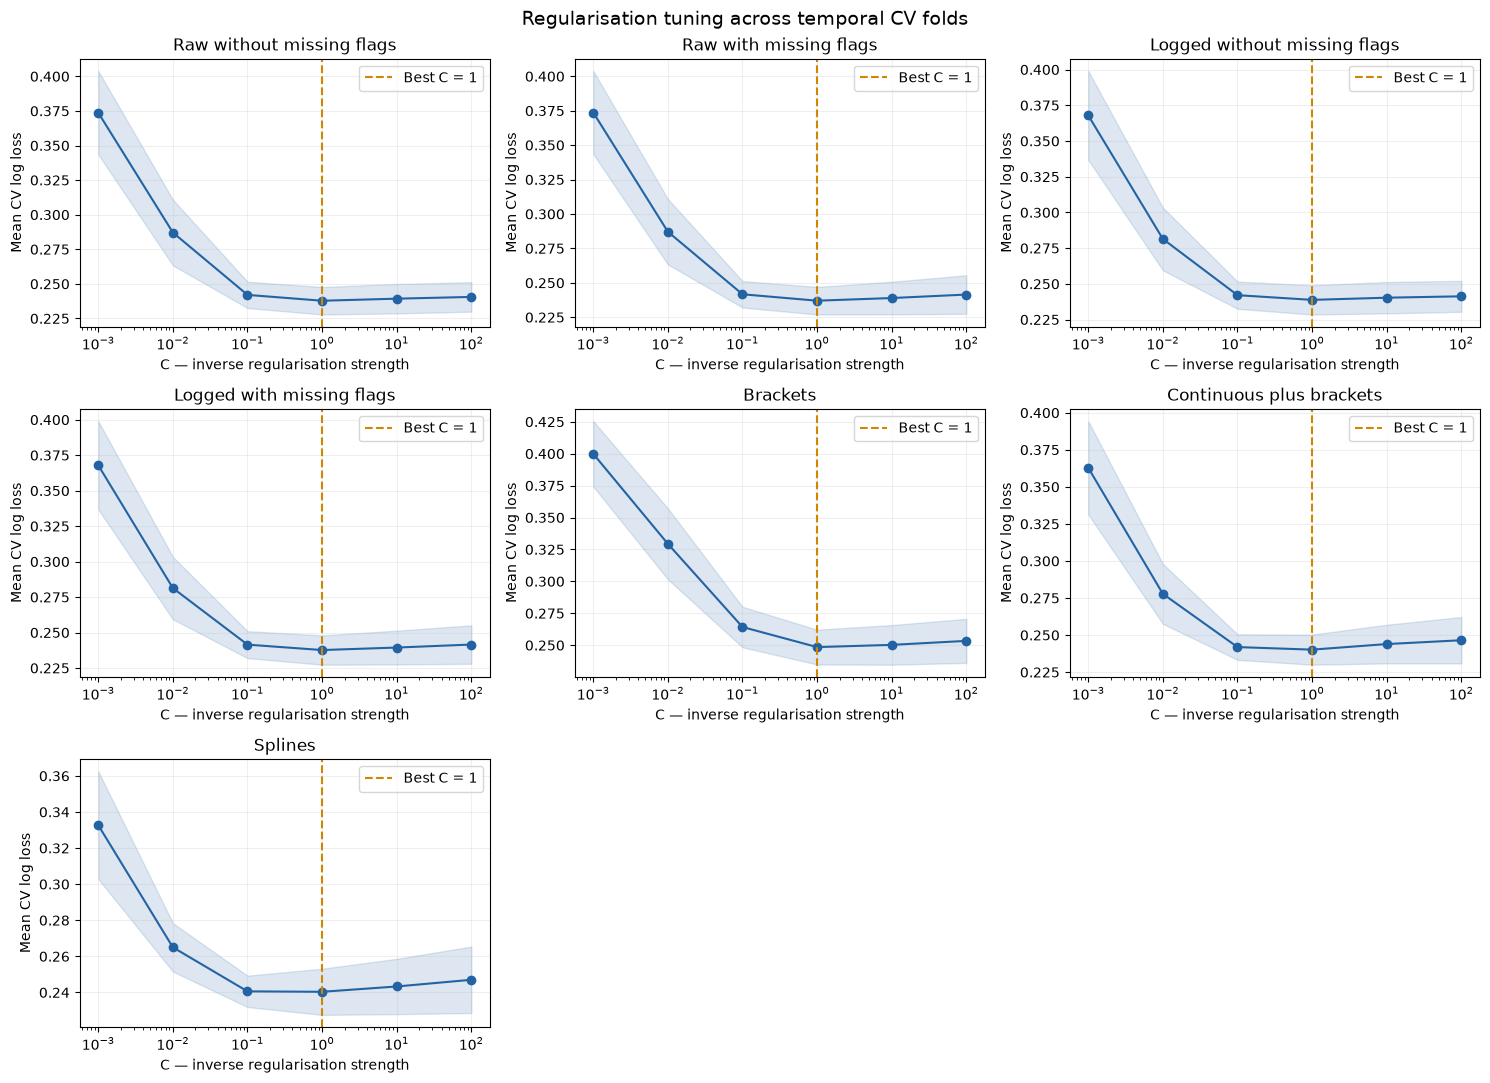

In [54]:
model_names = list(
    comparison_feature_sets.keys()
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 11)
)

axes = axes.flatten()

for axis, model_name in zip(
    axes,
    model_names
):
    model_results = (
        C_diagnostics.loc[
            C_diagnostics["model"] == model_name
        ]
        .sort_values("C")
    )

    best_C = tuning_searches[
        model_name
    ].best_params_["classifier__C"]

    axis.plot(
        model_results["C"],
        model_results["mean_cv_log_loss"],
        marker="o",
        color="#2463A3"
    )

    axis.fill_between(
        model_results["C"],
        (
            model_results["mean_cv_log_loss"]
            - model_results["std_cv_log_loss"]
        ),
        (
            model_results["mean_cv_log_loss"]
            + model_results["std_cv_log_loss"]
        ),
        color="#2463A3",
        alpha=0.15
    )

    axis.axvline(
        best_C,
        color="#D08700",
        linestyle="--",
        label=f"Best C = {best_C:g}"
    )

    axis.set_xscale("log")
    axis.set_title(model_name)
    axis.set_xlabel("C — inverse regularisation strength")
    axis.set_ylabel("Mean CV log loss")
    axis.grid(alpha=0.2)
    axis.legend()

for axis in axes[len(model_names):]:
    axis.set_visible(False)

fig.suptitle(
    "Regularisation tuning across temporal CV folds",
    fontsize=14
)

fig.tight_layout()
plt.show()

In [52]:
tuned_validation_results = (
    pd.DataFrame(tuned_result_records)
    .set_index("model")
)

result_columns = [
    "best_C",
    "cv_roc_auc",
    "cv_average_precision",
    "cv_log_loss",
    "roc_auc",
    "average_precision",
    "log_loss",
    "brier_score",
    "mean_predicted_default",
    "actual_default_rate"
]

tuned_validation_results[
    result_columns
].round(4)

,best_C,cv_roc_auc,cv_average_precision,cv_log_loss,roc_auc,average_precision,log_loss,brier_score,mean_predicted_default,actual_default_rate
model,,,,,,,,,,
Raw without missing flags,1.0,0.9248,0.7090,0.2378,0.9296,0.7161,0.2434,0.0777,0.1588,0.1683
Raw with missing flags,1.0,0.9255,0.7104,0.2370,0.9277,0.7085,0.2456,0.0785,0.1584,0.1683
Logged without missing flags,1.0,0.9240,0.7096,0.2388,0.9296,0.7170,0.2436,0.0776,0.1585,0.1683
Logged with missing flags,1.0,0.9250,0.7111,0.2377,0.9278,0.7096,0.2462,0.0784,0.1579,0.1683
Brackets,1.0,0.9174,0.6902,0.2485,0.9253,0.7053,0.2495,0.0797,0.1588,0.1683
Continuous plus brackets,1.0,0.9234,0.7071,0.2402,0.9273,0.7044,0.2466,0.0791,0.1586,0.1683
Splines,1.0,0.9237,0.7056,0.2404,0.9258,0.7042,0.2483,0.0794,0.1585,0.1683


## Regularisation type comparisons for top performers

In [75]:
finalist_names = [
    "Raw without missing flags",
    "Logged without missing flags",
    "Continuous plus brackets"
]

regularisation_grid = [
    {
        "classifier__penalty": ["l2"],
        "classifier__solver": ["lbfgs"],
        "classifier__C": C_grid
    },
    {
        "classifier__penalty": ["l1"],
        "classifier__solver": ["saga"],
        "classifier__C": C_grid
    },
    {
        "classifier__penalty": ["elasticnet"],
        "classifier__solver": ["saga"],
        "classifier__C": C_grid,
        "classifier__l1_ratio": [
            0.25,
            0.50,
            0.75
        ]
    }
]

In [76]:
regularisation_searches = {}
regularisation_models = {}
regularisation_predictions = {}
regularisation_result_records = []

for model_name in finalist_names:
    feature_set = comparison_feature_sets[
        model_name
    ]

    preprocessor = build_preprocessor(
        continuous_features=feature_set[
            "continuous_features"
        ],
        binary_features=feature_set[
            "binary_features"
        ],
        categorical_features=feature_set[
            "categorical_features"
        ],
        spline_features=feature_set[
            "spline_features"
        ],
        spline_n_knots=4,
        spline_degree=2
    )

    base_pipeline = build_logistic_pipeline(
        preprocessor=preprocessor,
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        class_weight=None,
        random_state=42
    )

    search = GridSearchCV(
        estimator=base_pipeline,
        param_grid=regularisation_grid,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
            "neg_log_loss": "neg_log_loss"
        },
        refit="neg_log_loss",
        cv=temporal_cv_splits,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    search.fit(
        X_development_all,
        y_development
    )

    best_model = search.best_estimator_
    best_position = search.best_index_
    best_parameters = search.best_params_

    validation_result = evaluate_probability_model(
        model_name=model_name,
        model=best_model,
        X=X_validation_all,
        y=y_validation
    )

    validation_result["average_precision"] = (
        validation_result.pop("pr_auc")
    )

    validation_result["penalty"] = (
        best_parameters["classifier__penalty"]
    )

    validation_result["solver"] = (
        best_parameters["classifier__solver"]
    )

    validation_result["best_C"] = (
        best_parameters["classifier__C"]
    )

    validation_result["l1_ratio"] = (
        best_parameters.get(
            "classifier__l1_ratio",
            np.nan
        )
    )

    validation_result["cv_roc_auc"] = (
        search.cv_results_[
            "mean_test_roc_auc"
        ][best_position]
    )

    validation_result["cv_average_precision"] = (
        search.cv_results_[
            "mean_test_average_precision"
        ][best_position]
    )

    validation_result["cv_log_loss"] = -(
        search.cv_results_[
            "mean_test_neg_log_loss"
        ][best_position]
    )

    coefficients = (
        best_model
        .named_steps["classifier"]
        .coef_
        .ravel()
    )

    validation_result["nonzero_coefficients"] = int(
        np.count_nonzero(
            np.abs(coefficients) > 1e-8
        )
    )

    validation_result["total_coefficients"] = len(
        coefficients
    )

    regularisation_searches[model_name] = search
    regularisation_models[model_name] = best_model
    regularisation_predictions[model_name] = (
        best_model.predict_proba(
            X_validation_all
        )[:, 1]
    )
    regularisation_result_records.append(
        validation_result
    )

    print(
        f"{model_name}: "
        f"penalty={validation_result['penalty']}, "
        f"C={validation_result['best_C']}, "
        f"l1_ratio={validation_result['l1_ratio']}"
    )

Raw without missing flags: penalty=elasticnet, C=1.0, l1_ratio=0.25
Logged without missing flags: penalty=l1, C=1.0, l1_ratio=nan
Continuous plus brackets: penalty=l1, C=1.0, l1_ratio=nan


In [77]:
regularisation_results = (
    pd.DataFrame(
        regularisation_result_records
    )
    .set_index("model")
)

regularisation_columns = [
    "penalty",
    "solver",
    "best_C",
    "l1_ratio",
    "cv_roc_auc",
    "cv_average_precision",
    "cv_log_loss",
    "roc_auc",
    "average_precision",
    "log_loss",
    "brier_score",
    "mean_predicted_default",
    "actual_default_rate",
    "nonzero_coefficients",
    "total_coefficients"
]

regularisation_results[
    regularisation_columns
].round(4)

,penalty,solver,best_C,l1_ratio,cv_roc_auc,cv_average_precision,cv_log_loss,roc_auc,average_precision,log_loss,brier_score,mean_predicted_default,actual_default_rate,nonzero_coefficients,total_coefficients
model,,,,,,,,,,,,,,,
Raw without missing flags,elasticnet,saga,1.0,0.25,0.9248,0.7090,0.2377,0.9296,0.7167,0.2432,0.0776,0.1590,0.1683,19,21
Logged without missing flags,l1,saga,1.0,NaN,0.9243,0.7106,0.2386,0.9294,0.7164,0.2438,0.0776,0.1587,0.1683,15,21
Continuous plus brackets,l1,saga,1.0,NaN,0.9238,0.7089,0.2394,0.9278,0.7064,0.2458,0.0788,0.1587,0.1683,31,45


In [78]:
penalty_comparison_records = []

for feature_set_name, search in regularisation_searches.items():
    search_results = pd.DataFrame(
        search.cv_results_
    )

    search_results["penalty"] = search_results[
        "param_classifier__penalty"
    ].astype(str)

    search_results["C"] = search_results[
        "param_classifier__C"
    ].astype(float)

    search_results["cv_log_loss"] = -search_results[
        "mean_test_neg_log_loss"
    ]

    search_results["cv_roc_auc"] = search_results[
        "mean_test_roc_auc"
    ]

    search_results["cv_average_precision"] = search_results[
        "mean_test_average_precision"
    ]

    for penalty in ["l2", "l1", "elasticnet"]:
        penalty_results = search_results.loc[
            search_results["penalty"] == penalty
        ]

        best_row = penalty_results.loc[
            penalty_results["cv_log_loss"].idxmin()
        ]

        if penalty == "elasticnet":
            l1_ratio = float(
                best_row[
                    "param_classifier__l1_ratio"
                ]
            )
        else:
            l1_ratio = np.nan

        penalty_comparison_records.append({
            "feature_set": feature_set_name,
            "penalty": penalty,
            "best_C": best_row["C"],
            "l1_ratio": l1_ratio,
            "cv_roc_auc": best_row["cv_roc_auc"],
            "cv_average_precision": (
                best_row["cv_average_precision"]
            ),
            "cv_log_loss": best_row["cv_log_loss"]
        })

penalty_comparison = (
    pd.DataFrame(penalty_comparison_records)
    .set_index(["feature_set", "penalty"])
)

penalty_comparison.round(4)

best_C  l1_ratio  cv_roc_auc  \
feature_set                  penalty                                    
Raw without missing flags    l2             1.0       NaN      0.9248   
                             l1             1.0       NaN      0.9249   
                             elasticnet     1.0      0.25      0.9248   
Logged without missing flags l2             1.0       NaN      0.9240   
                             l1             1.0       NaN      0.9243   
                             elasticnet     1.0      0.50      0.9242   
Continuous plus brackets     l2             1.0       NaN      0.9234   
                             l1             1.0       NaN      0.9238   
                             elasticnet     1.0      0.75      0.9238   

                                         cv_average_precision  cv_log_loss  
feature_set                  penalty                                        
Raw without missing flags    l2                        0.7090       0.2378  
                             l1                        0.7095       0.2378  
                             elasticnet                0.7090       0.2377  
Logged without missing flags l2                        0.7096       0.2388  
                             l1                        0.7106       0.2386  
                             elasticnet                0.7100       0.2386  
Continuous plus brackets     l2                        0.7071       0.2402  
                             l1                        0.7089       0.2394  
                             elasticnet                0.7086       0.2395

# Final Model operations 

## Refit on entire training set

In [81]:
raw_preprocessor = build_preprocessor(
    **comparison_feature_sets["Raw without missing flags"]
)

bracket_preprocessor = build_preprocessor(
    **comparison_feature_sets["Continuous plus brackets"]
)

final_model = build_logistic_pipeline(
    preprocessor=raw_preprocessor,
    C=1.0,
    penalty="l2",
    solver="lbfgs"
)

bracket_model = build_logistic_pipeline(
    preprocessor=bracket_preprocessor,
    C=1.0,
    penalty="l1",
    solver="saga"
)

X_train_final = train.drop(columns=["target_var", "OBS_DATE"])
y_train_final = train["target_var"].astype(int)

X_test = test.drop(columns=["target_var", "OBS_DATE"])
y_test = test["target_var"].astype(int)

assert train["OBS_DATE"].max() < test["OBS_DATE"].min()

dummy_test = Pipeline([
    ("preprocessing", clone(raw_preprocessor)),
    ("classifier", DummyClassifier(strategy="prior"))
])

schufa_preprocessor = build_preprocessor(
    continuous_features=["schufa"],
    binary_features=[],
    categorical_features=[],
    spline_features=[]
)

schufa_test = build_logistic_pipeline(
    preprocessor=schufa_preprocessor,
    C=1.0,
    penalty="l2",
    solver="lbfgs"
)

dummy_test.fit(X_train_final, y_train_final)
schufa_test.fit(X_train_final[["schufa"]], y_train_final)
final_model.fit(X_train_final, y_train_final)
bracket_model.fit(X_train_final, y_train_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['income','loan_amount','term_length',...,'schufa_missing','schufa_log', 'schufa_bracket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that

## Test Set evaluation

In [82]:
final_test_results = pd.DataFrame([
    evaluate_probability_model(
        "Dummy prior", dummy_test, X_test, y_test
    ),
    evaluate_probability_model(
        "SCHUFA-only logistic",
        schufa_test,
        X_test[["schufa"]],
        y_test
    ),
    evaluate_probability_model(
        "Raw continuous — L2",
        final_model,
        X_test,
        y_test
    ),
    evaluate_probability_model(
        "Continuous plus brackets — L1",
        bracket_model,
        X_test,
        y_test
    )
]).set_index("model")

final_test_results.round(4)

,roc_auc,pr_auc,log_loss,brier_score,mean_predicted_default,actual_default_rate
model,,,,,,
Dummy prior,0.5000,0.1551,0.4315,0.1311,0.1532,0.1551
SCHUFA-only logistic,0.7717,0.3465,0.3659,0.1154,0.1629,0.1551
Raw continuous — L2,0.9236,0.7137,0.2378,0.0746,0.1551,0.1551
Continuous plus brackets — L1,0.9231,0.7092,0.2387,0.0750,0.1548,0.1551


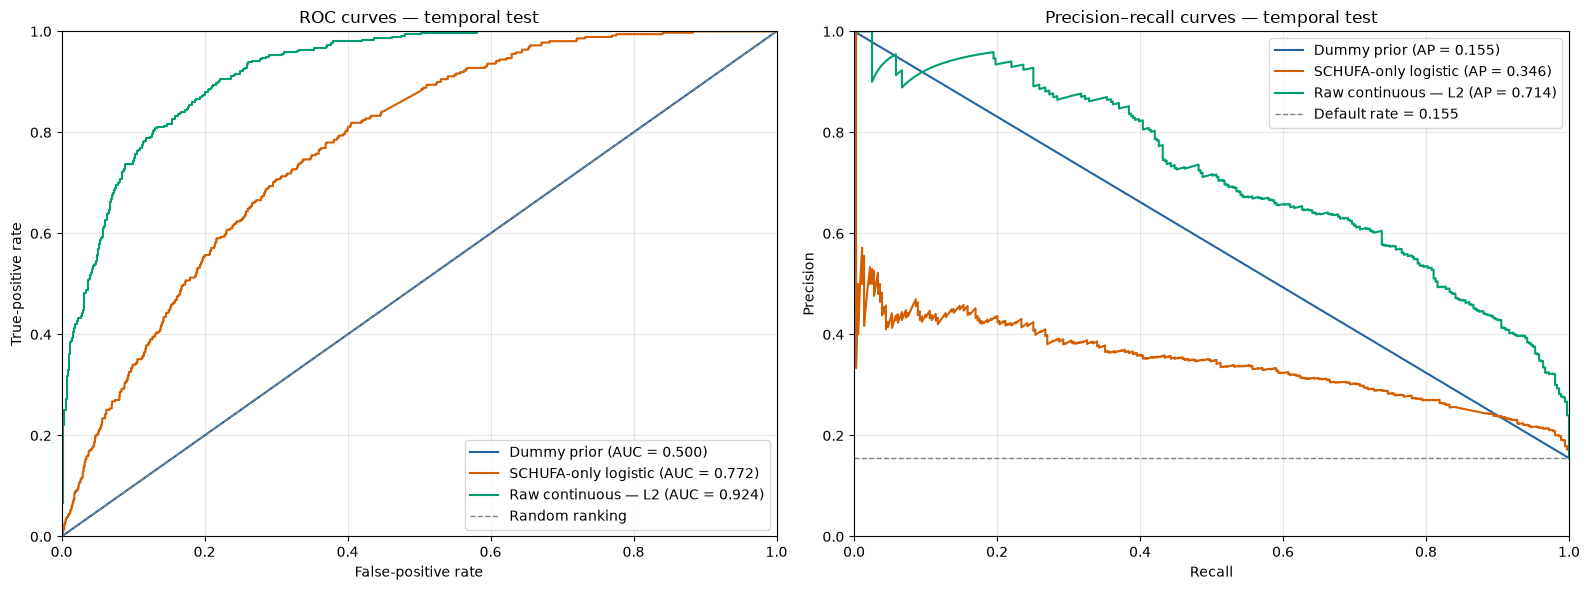

In [118]:
test_predictions = {
    "Dummy prior": dummy_test.predict_proba(X_test)[:, 1],
    "SCHUFA-only logistic":
        schufa_test.predict_proba(X_test[["schufa"]])[:, 1],
    "Raw continuous — L2":
        final_model.predict_proba(X_test)[:, 1]
    # "Continuous plus brackets — L1":
    #     bracket_model.predict_proba(X_test)[:, 1]
}

model_styles = {
    "Dummy prior": {"color": "#4C78A8", "linestyle": "-"},
    "SCHUFA-only logistic": {"color": "#F58518", "linestyle": "-"},
    "Raw continuous — L2": {"color": "#10A778", "linestyle": "-"}
    # "Continuous plus brackets — L1": {
    #     "color": "#B279A2",
    #     "linestyle": "-"
    # }
}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_roc_curves(
    y_test,
    test_predictions,
    ax=axes[0],
    title="ROC curves — temporal test"
)

plot_precision_recall_curves(
    y_test,
    test_predictions,
    ax=axes[1],
    title="Precision–recall curves — temporal test"
)

# plot_calibration_curves(
#     y_test,
#     test_predictions,
#     ax=axes[2],
#     title="Calibration curves — temporal test"
# )

plt.tight_layout()
plt.show()

# Visuals

In [102]:
split_frames = {
    "Development": development_df,
    "Validation": validation_df,
    "Test": test
}

split_summary = pd.DataFrame({
    name: {
        "Rows": len(df),
        "Defaults": df["target_var"].sum(),
        "Default rate": df["target_var"].mean(),
        "Start": df["OBS_DATE"].min(),
        "End": df["OBS_DATE"].max()
    }
    for name, df in split_frames.items()
}).T

split_summary

,Rows,Defaults,Default rate,Start,End
Development,5268,787,0.149393,2008-01-02 00:00:00,2014-07-15 00:00:00
Validation,1319,222,0.168309,2014-07-16 00:00:00,2016-03-16 00:00:00
Test,2314,359,0.155143,2016-03-17 00:00:00,2018-12-31 00:00:00


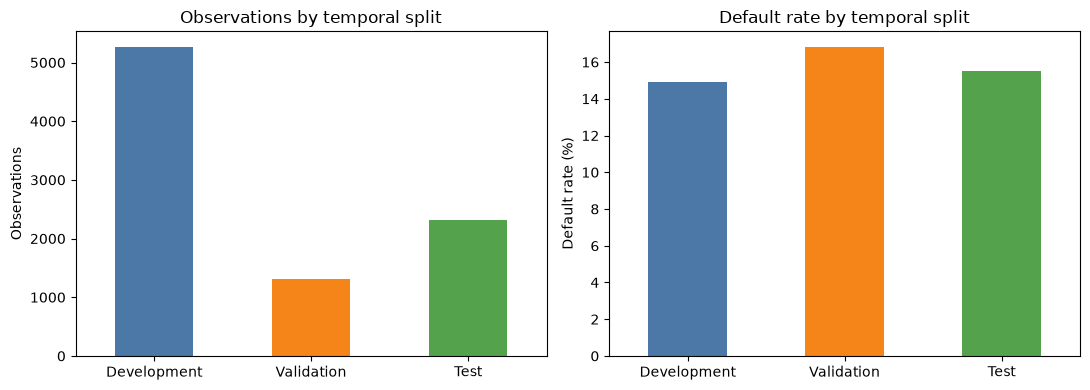

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

split_summary["Rows"].plot.bar(
    ax=axes[0], color=["#4C78A8", "#F58518", "#54A24B"]
)
axes[0].set_title("Observations by temporal split")
axes[0].set_ylabel("Observations")
axes[0].tick_params(axis="x", rotation=0)

(split_summary["Default rate"] * 100).plot.bar(
    ax=axes[1], color=["#4C78A8", "#F58518", "#54A24B"]
)
axes[1].set_title("Default rate by temporal split")
axes[1].set_ylabel("Default rate (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

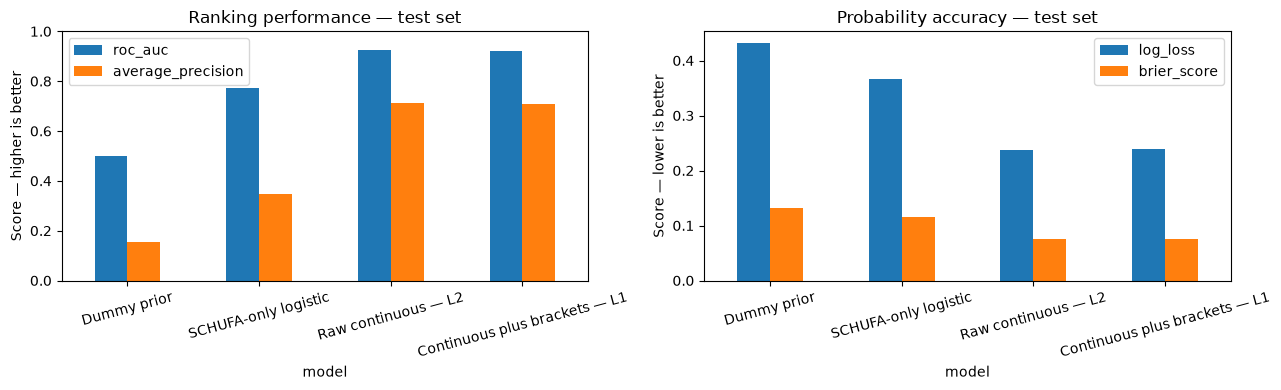

In [104]:
comparison = final_test_results.rename(columns={
    "pr_auc": "average_precision"
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

comparison[["roc_auc", "average_precision"]].plot.bar(ax=axes[0])
axes[0].set_title("Ranking performance — test set")
axes[0].set_ylabel("Score — higher is better")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=15)

comparison[["log_loss", "brier_score"]].plot.bar(ax=axes[1])
axes[1].set_title("Probability accuracy — test set")
axes[1].set_ylabel("Score — lower is better")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

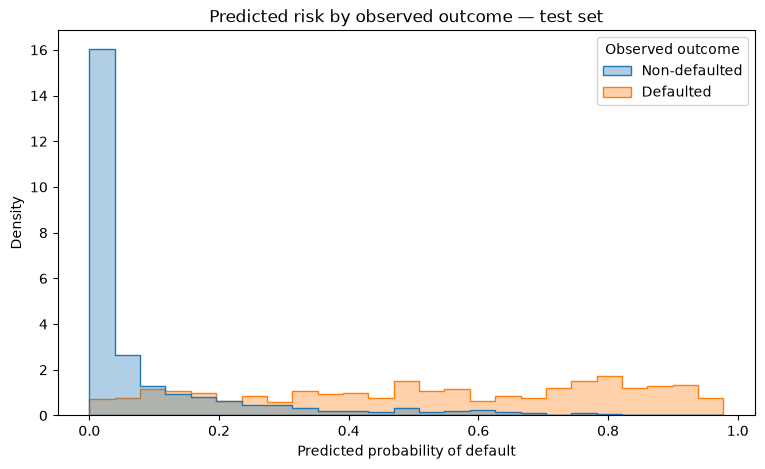

In [105]:
test_probability = final_model.predict_proba(X_test)[:, 1]

risk_plot_data = pd.DataFrame({
    "Predicted default probability": test_probability,
    "Observed outcome": np.where(
        y_test.eq(1), "Defaulted", "Non-defaulted"
    )
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=risk_plot_data,
    x="Predicted default probability",
    hue="Observed outcome",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.35
)

plt.title("Predicted risk by observed outcome — test set")
plt.xlabel("Predicted probability of default")
plt.ylabel("Density")
plt.show()

In [106]:
from sklearn.base import clone
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

X_development = development_df.drop(columns=["target_var", "OBS_DATE"])
y_development = development_df["target_var"].astype(int)

X_validation = validation_df.drop(columns=["target_var", "OBS_DATE"])
y_validation = validation_df["target_var"].astype(int)

threshold_model = clone(final_model).fit(X_development, y_development)
validation_probability = threshold_model.predict_proba(X_validation)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_validation, validation_probability
)

f1 = 2 * precision[:-1] * recall[:-1] / (
    precision[:-1] + recall[:-1] + 1e-12
)

selected_threshold = thresholds[np.argmax(f1)]
selected_threshold

np.float64(0.4307097672593998)

Threshold                   0.431
Precision                   0.650
Recall                      0.616
Specificity                 0.939
F1 score                    0.632
Predicted high-risk rate    0.147
dtype: float64

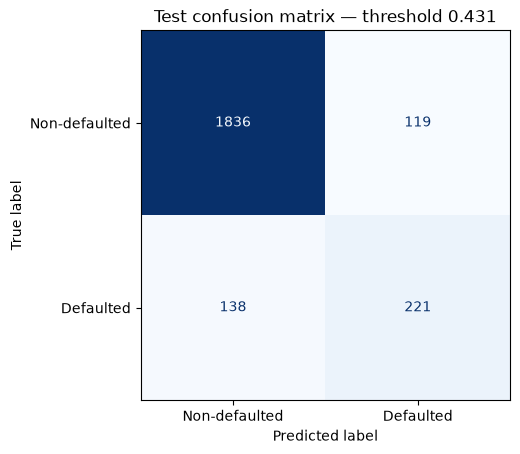

In [72]:
test_prediction = (test_probability >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_prediction, labels=[0, 1]
).ravel()

threshold_results = pd.Series({
    "Threshold": selected_threshold,
    "Precision": precision_score(y_test, test_prediction),
    "Recall": recall_score(y_test, test_prediction),
    "Specificity": tn / (tn + fp),
    "F1 score": f1_score(y_test, test_prediction),
    "Predicted high-risk rate": test_prediction.mean()
})

display(threshold_results.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    display_labels=["Non-defaulted", "Defaulted"],
    cmap="Blues",
    colorbar=False
)

plt.title(f"Test confusion matrix — threshold {selected_threshold:.3f}")
plt.show()

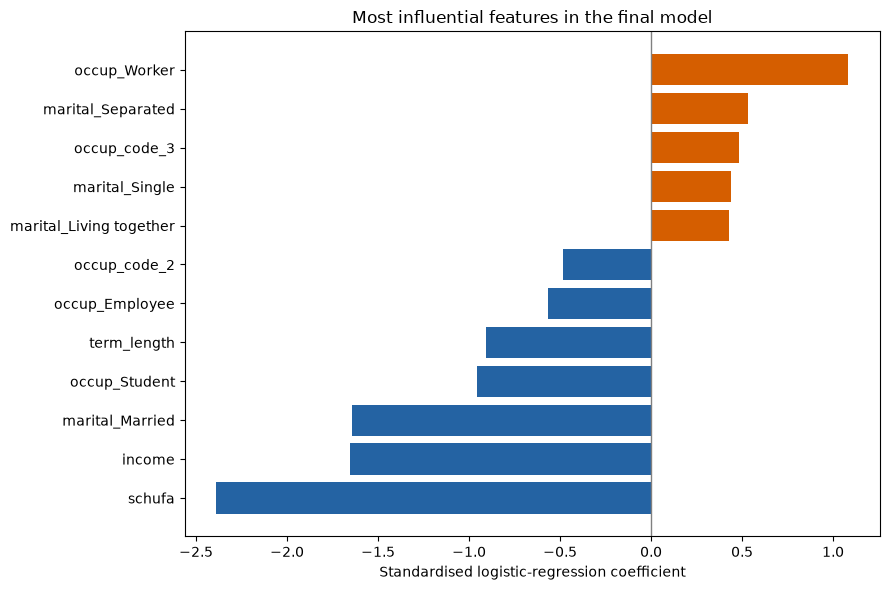

In [73]:
feature_names = (
    final_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": final_model.named_steps["classifier"].coef_[0]
})

coefficients["feature"] = coefficients["feature"].str.replace(
    r"^[^_]+__", "", regex=True
)

top_coefficients = (
    coefficients
    .assign(absolute=lambda df: df["coefficient"].abs())
    .nlargest(12, "absolute")
    .sort_values("coefficient")
)

colours = np.where(
    top_coefficients["coefficient"] > 0,
    "#D55E00",
    "#2463A3"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"],
    color=colours
)
plt.axvline(0, color="grey", linewidth=1)
plt.title("Most influential features in the final model")
plt.xlabel("Standardised logistic-regression coefficient")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [92]:
model_for_shap = final_model

preprocessor = model_for_shap.named_steps["preprocessing"]
classifier = model_for_shap.named_steps["classifier"]

X_train_shap = preprocessor.transform(X_train_final)
X_test_shap = preprocessor.transform(X_test)

if hasattr(X_train_shap, "toarray"):
    X_train_shap = X_train_shap.toarray()
    X_test_shap = X_test_shap.toarray()

feature_names = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

X_train_shap = pd.DataFrame(X_train_shap, columns=feature_names)
X_test_shap = pd.DataFrame(X_test_shap, columns=feature_names)

explainer = shap.LinearExplainer(classifier, X_train_shap)
shap_values = explainer(X_test_shap)

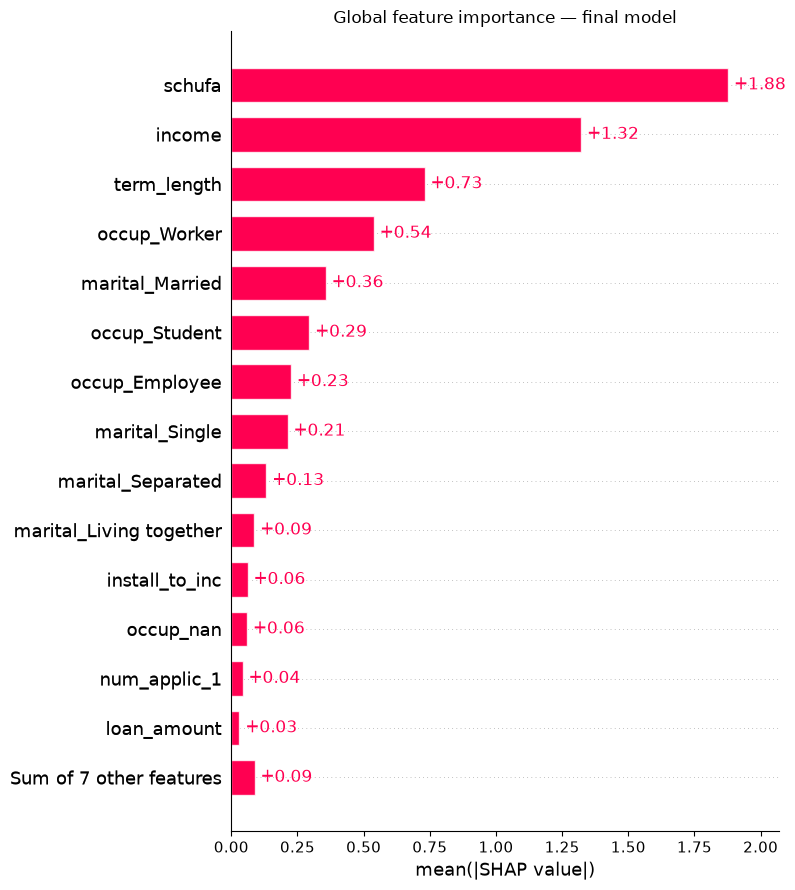

In [93]:
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Global feature importance — final model")
plt.tight_layout()
plt.show()

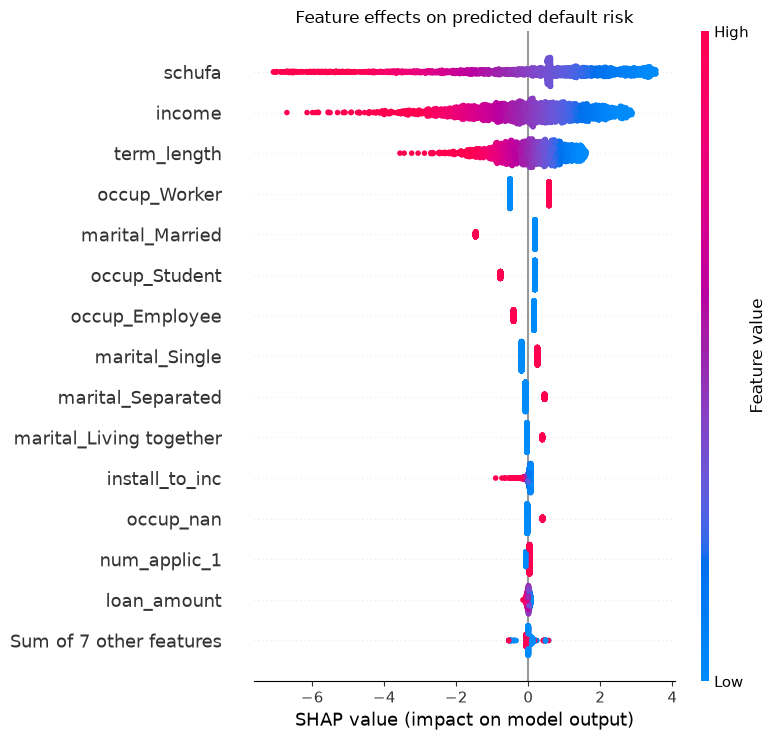

In [94]:
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Feature effects on predicted default risk")
plt.tight_layout()
plt.show()

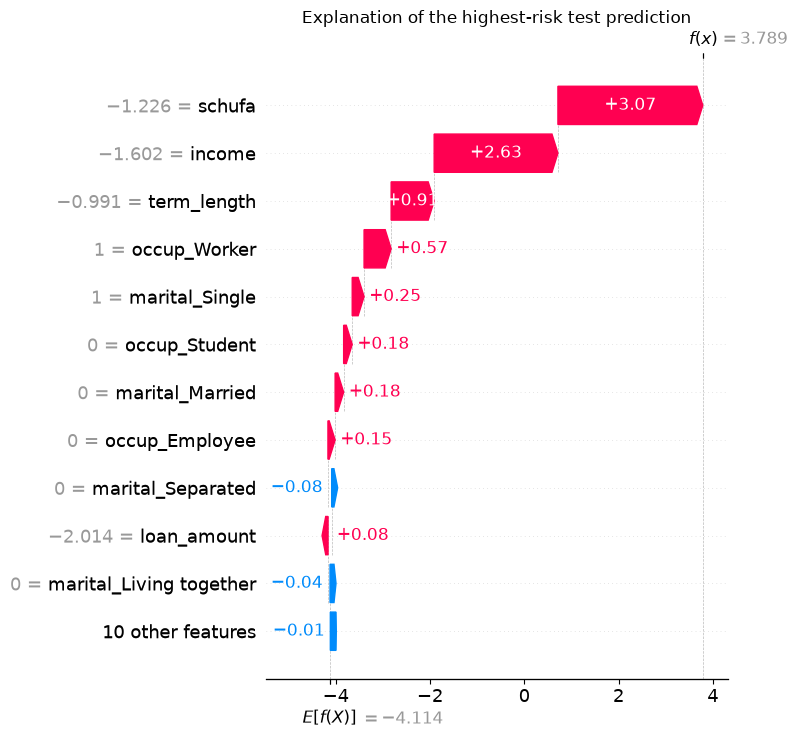

In [95]:
highest_risk_index = np.argmax(test_probability)

shap.plots.waterfall(
    shap_values[highest_risk_index],
    max_display=12,
    show=False
)

plt.title("Explanation of the highest-risk test prediction")
plt.tight_layout()
plt.show()

## Bracket Model

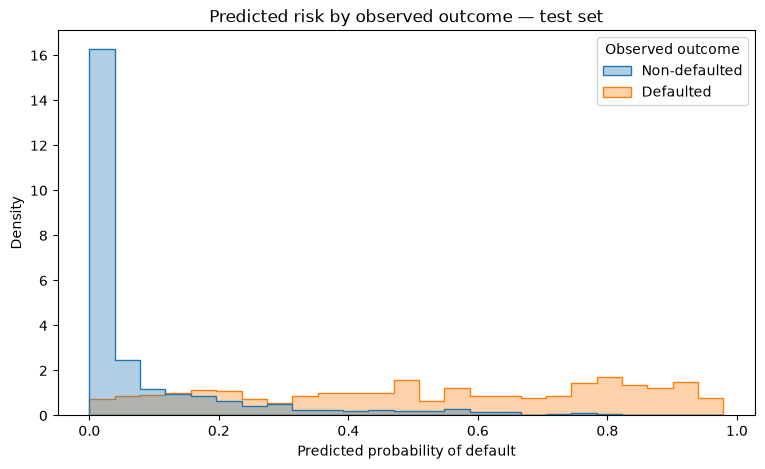

In [87]:
test_probability = bracket_model.predict_proba(X_test)[:, 1]

risk_plot_data = pd.DataFrame({
    "Predicted default probability": test_probability,
    "Observed outcome": np.where(
        y_test.eq(1), "Defaulted", "Non-defaulted"
    )
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=risk_plot_data,
    x="Predicted default probability",
    hue="Observed outcome",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.35
)

plt.title("Predicted risk by observed outcome — test set")
plt.xlabel("Predicted probability of default")
plt.ylabel("Density")
plt.show()

In [88]:
from sklearn.base import clone
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

X_development = development_df.drop(columns=["target_var", "OBS_DATE"])
y_development = development_df["target_var"].astype(int)

X_validation = validation_df.drop(columns=["target_var", "OBS_DATE"])
y_validation = validation_df["target_var"].astype(int)

threshold_model = clone(bracket_model).fit(X_development, y_development)
validation_probability = threshold_model.predict_proba(X_validation)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_validation, validation_probability
)

f1 = 2 * precision[:-1] * recall[:-1] / (
    precision[:-1] + recall[:-1] + 1e-12
)

selected_threshold = thresholds[np.argmax(f1)]
selected_threshold

np.float64(0.2091361610570559)

Threshold                   0.209
Precision                   0.507
Recall                      0.797
Specificity                 0.858
F1 score                    0.620
Predicted high-risk rate    0.244
dtype: float64

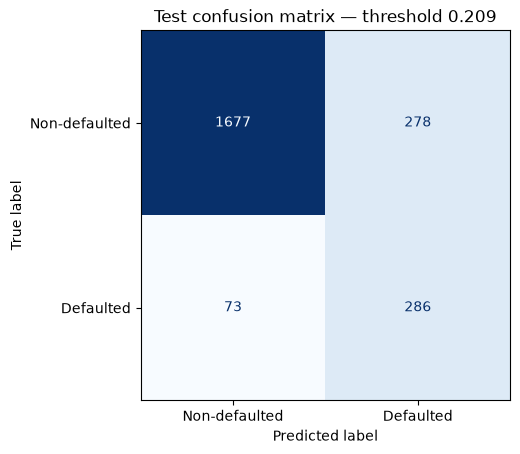

In [89]:
test_prediction = (test_probability >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_prediction, labels=[0, 1]
).ravel()

threshold_results = pd.Series({
    "Threshold": selected_threshold,
    "Precision": precision_score(y_test, test_prediction),
    "Recall": recall_score(y_test, test_prediction),
    "Specificity": tn / (tn + fp),
    "F1 score": f1_score(y_test, test_prediction),
    "Predicted high-risk rate": test_prediction.mean()
})

display(threshold_results.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    display_labels=["Non-defaulted", "Defaulted"],
    cmap="Blues",
    colorbar=False
)

plt.title(f"Test confusion matrix — threshold {selected_threshold:.3f}")
plt.show()

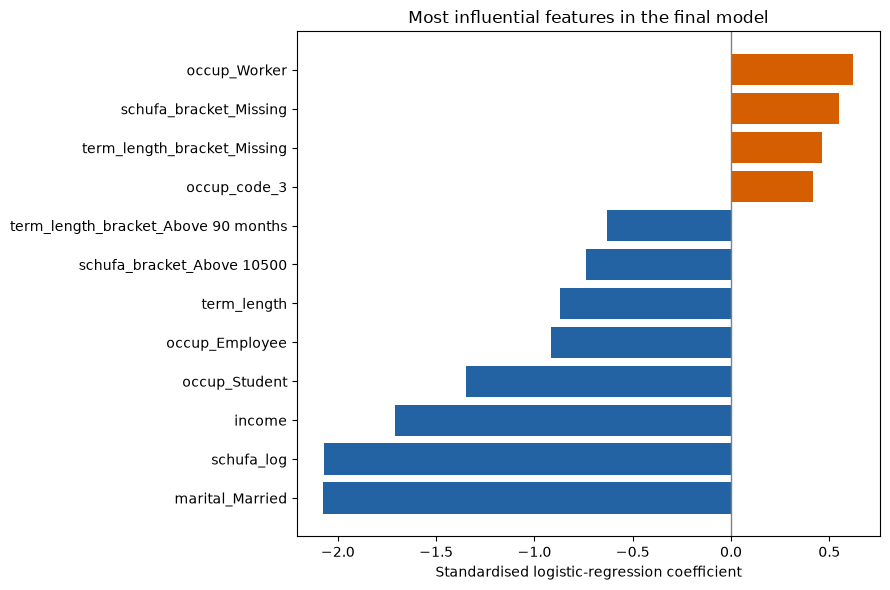

In [96]:
feature_names = (
    bracket_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": bracket_model.named_steps["classifier"].coef_[0]
})

coefficients["feature"] = coefficients["feature"].str.replace(
    r"^[^_]+__", "", regex=True
)

top_coefficients = (
    coefficients
    .assign(absolute=lambda df: df["coefficient"].abs())
    .nlargest(12, "absolute")
    .sort_values("coefficient")
)

colours = np.where(
    top_coefficients["coefficient"] > 0,
    "#D55E00",
    "#2463A3"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"],
    color=colours
)
plt.axvline(0, color="grey", linewidth=1)
plt.title("Most influential features in the final model")
plt.xlabel("Standardised logistic-regression coefficient")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [97]:
model_for_shap = bracket_model

preprocessor = model_for_shap.named_steps["preprocessing"]
classifier = model_for_shap.named_steps["classifier"]

X_train_shap = preprocessor.transform(X_train_final)
X_test_shap = preprocessor.transform(X_test)

if hasattr(X_train_shap, "toarray"):
    X_train_shap = X_train_shap.toarray()
    X_test_shap = X_test_shap.toarray()

feature_names = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

X_train_shap = pd.DataFrame(X_train_shap, columns=feature_names)
X_test_shap = pd.DataFrame(X_test_shap, columns=feature_names)

explainer = shap.LinearExplainer(classifier, X_train_shap)
shap_values = explainer(X_test_shap)

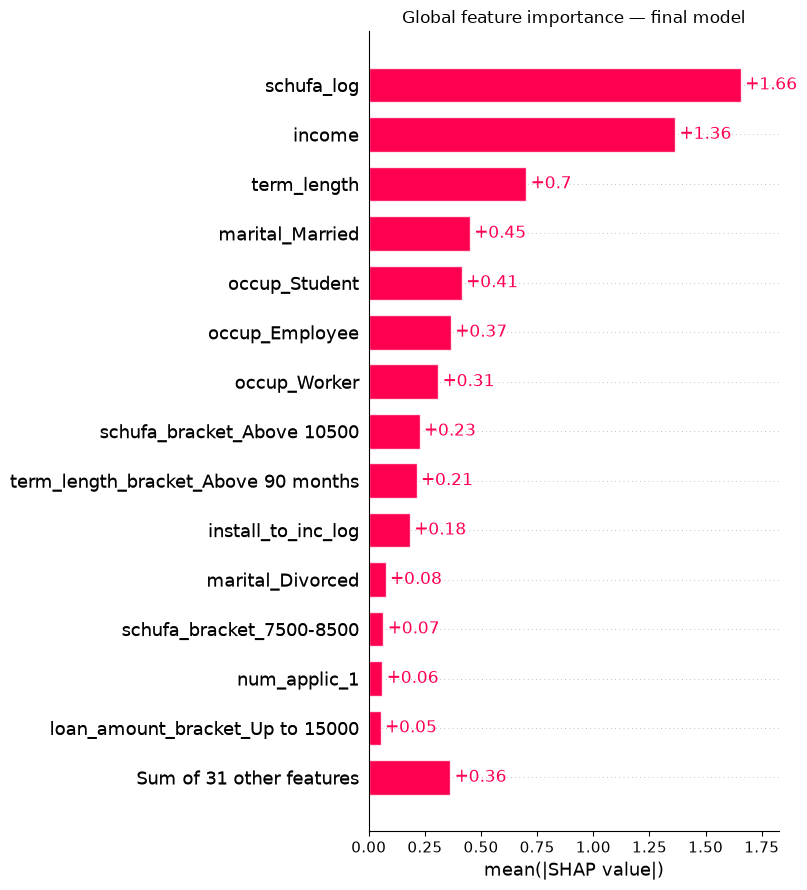

In [98]:
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Global feature importance — final model")
plt.tight_layout()
plt.show()

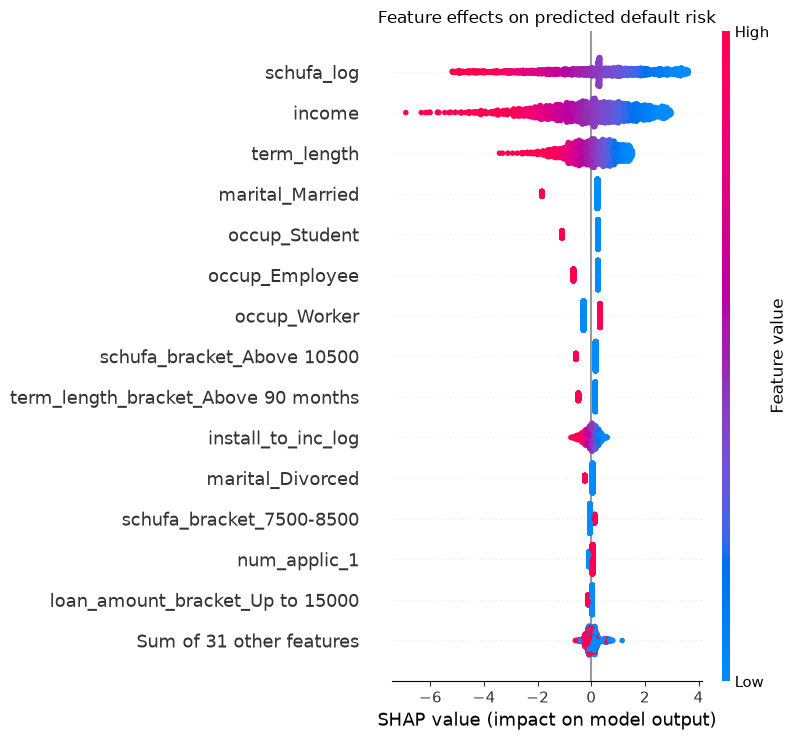

In [99]:
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Feature effects on predicted default risk")
plt.tight_layout()
plt.show()

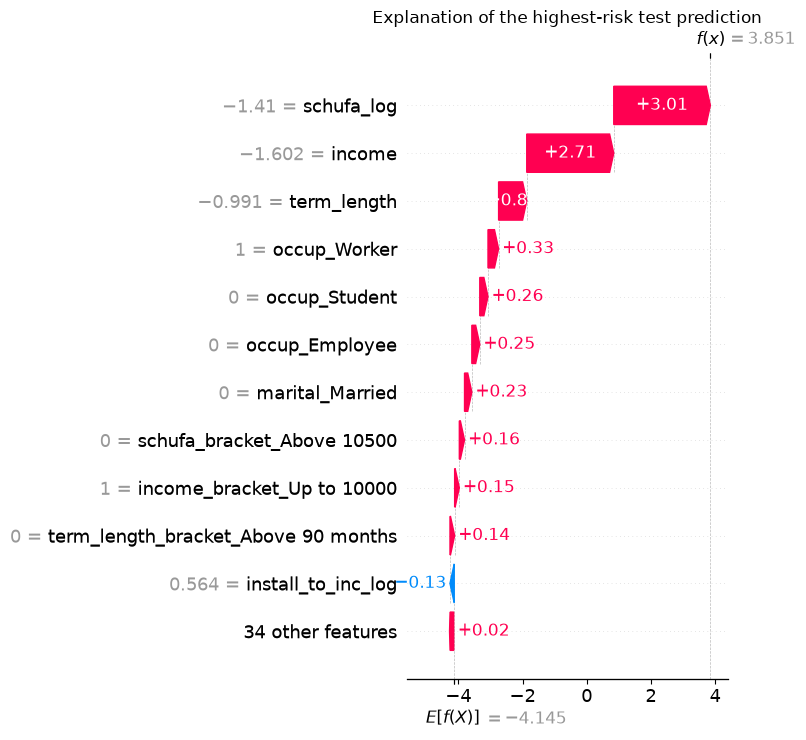

In [100]:
highest_risk_index = np.argmax(test_probability)

shap.plots.waterfall(
    shap_values[highest_risk_index],
    max_display=12,
    show=False
)

plt.title("Explanation of the highest-risk test prediction")
plt.tight_layout()
plt.show()

## Models Validation Runs comparison

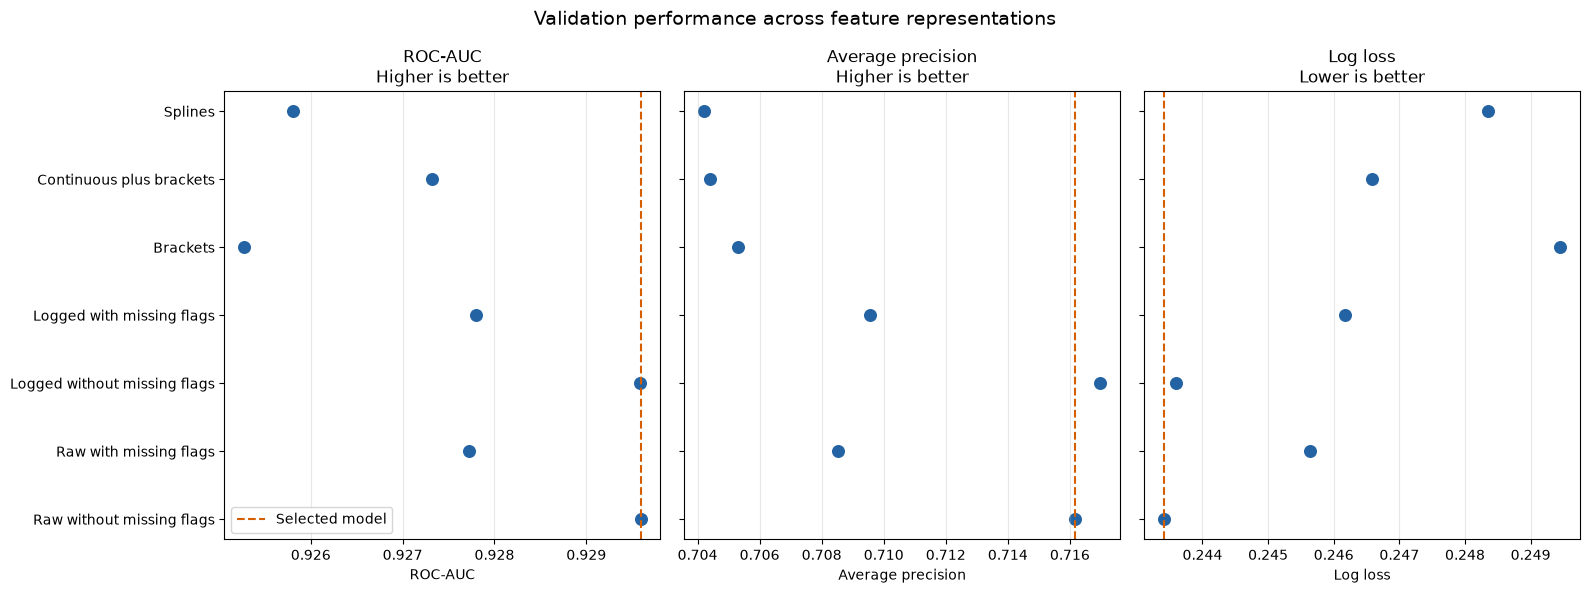

In [74]:
feature_order = [
    "Raw without missing flags",
    "Raw with missing flags",
    "Logged without missing flags",
    "Logged with missing flags",
    "Brackets",
    "Continuous plus brackets",
    "Splines"
]

plot_results = all_validation_results.loc[feature_order]

metrics = {
    "roc_auc": ("ROC-AUC", "Higher is better"),
    "pr_auc": ("Average precision", "Higher is better"),
    "log_loss": ("Log loss", "Lower is better")
}

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

for ax, (metric, (title, direction)) in zip(axes, metrics.items()):
    values = plot_results[metric]

    ax.scatter(values, feature_order, s=70, color="#2463A3")
    ax.axvline(
        values.loc["Raw without missing flags"],
        color="#D55E00",
        linestyle="--",
        label="Selected model"
    )

    ax.set_title(f"{title}\n{direction}")
    ax.set_xlabel(title)
    ax.grid(axis="x", alpha=0.3)

axes[0].legend()
fig.suptitle("Validation performance across feature representations", fontsize=14)
plt.tight_layout()
plt.show()

# Stats for presentation

In [107]:
test_decisions = test.loc[X_test.index, ["target_var", "loan_amount"]].copy()

test_decisions["schufa_score"] = schufa_test.predict_proba(
    X_test[["schufa"]]
)[:, 1]

test_decisions["final_score"] = final_model.predict_proba(X_test)[:, 1]
test_decisions["final_flag"] = test_decisions["final_score"] >= selected_threshold

n_flagged = test_decisions["final_flag"].sum()

test_decisions["schufa_flag"] = False
schufa_idx = test_decisions["schufa_score"].nlargest(n_flagged).index
test_decisions.loc[schufa_idx, "schufa_flag"] = True


def decision_metrics(data, flag_col):
    y = data["target_var"].astype(bool)
    flagged = data[flag_col].astype(bool)
    exposure = data["loan_amount"]
    exposure_available = exposure.notna()

    tp = (flagged & y).sum()
    fp = (flagged & ~y).sum()

    captured_exposure = exposure[
        flagged & y & exposure_available
    ].sum()

    total_default_exposure = exposure[
        y & exposure_available
    ].sum()

    return pd.Series({
        "applications_flagged": flagged.sum(),
        "flag_rate_pct": flagged.mean() * 100,
        "defaults_captured": tp,
        "trd_pct": tp / y.sum() * 100,
        "default_exposure_captured": captured_exposure,
        "vdr_pct": captured_exposure / total_default_exposure * 100,
        "false_positives": fp,
        "false_positive_share_pct": fp / flagged.sum() * 100,
        "false_positive_rate_pct": fp / (~y).sum() * 100,
        "precision_pct": tp / flagged.sum() * 100,
        "default_exposure_coverage_pct": exposure_available[y].mean() * 100
    })


decision_comparison = pd.DataFrame({
    "SCHUFA": decision_metrics(test_decisions, "schufa_flag"),
    "Final model": decision_metrics(test_decisions, "final_flag")
})

decision_comparison["change"] = (
    decision_comparison["Final model"]
    - decision_comparison["SCHUFA"]
)

before = decision_comparison["SCHUFA"]
after = decision_comparison["Final model"]

executive_metrics = pd.DataFrame({
    "metric": [
        "Default capture — TRD",
        "Value capture — VDR",
        "Defaults captured",
        "Defaulted exposure captured",
        "False-positive share"
    ],
    "SCHUFA": [
        f"{before['trd_pct']:.1f}%",
        f"{before['vdr_pct']:.1f}%",
        f"{before['defaults_captured']:.0f}",
        f"{before['default_exposure_captured']:,.0f}",
        f"{before['false_positive_share_pct']:.1f}%"
    ],
    "Final model": [
        f"{after['trd_pct']:.1f}%",
        f"{after['vdr_pct']:.1f}%",
        f"{after['defaults_captured']:.0f}",
        f"{after['default_exposure_captured']:,.0f}",
        f"{after['false_positive_share_pct']:.1f}%"
    ],
    "improvement": [
        f"{after['trd_pct'] - before['trd_pct']:+.1f} pp",
        f"{after['vdr_pct'] - before['vdr_pct']:+.1f} pp",
        f"{after['defaults_captured'] - before['defaults_captured']:+.0f}",
        f"{after['default_exposure_captured'] - before['default_exposure_captured']:+,.0f}",
        f"{before['false_positive_share_pct'] - after['false_positive_share_pct']:+.1f} pp"
    ]
})

display(decision_comparison.round(2))
display(executive_metrics)

,SCHUFA,Final model,change
applications_flagged,340.00,340.00,0.00
flag_rate_pct,14.69,14.69,0.00
defaults_captured,126.00,221.00,95.00
trd_pct,35.10,61.56,26.46
default_exposure_captured,2503200.00,3914100.00,1410900.00
vdr_pct,37.41,58.49,21.08
false_positives,214.00,119.00,-95.00
false_positive_share_pct,62.94,35.00,-27.94
false_positive_rate_pct,10.95,6.09,-4.86
precision_pct,37.06,65.00,27.94


,metric,SCHUFA,Final model,improvement
0,Default capture — TRD,35.1%,61.6%,+26.5 pp
1,Value capture — VDR,37.4%,58.5%,+21.1 pp
2,Defaults captured,126,221,+95
3,Defaulted exposure captured,"2,503,200","3,914,100","+1,410,900"
4,False-positive share,62.9%,35.0%,+27.9 pp


In [108]:
before = decision_comparison["SCHUFA"]
after = decision_comparison["Final model"]

def uplift_ratio(before_value, after_value, negative=False):
    if before_value == 0:
        return np.nan

    uplift = after_value / before_value * 100
    return -uplift if negative else uplift


final_executive_table = pd.DataFrame([{
    "TDR # capture before": before["defaults_captured"],
    "TDR # capture after": after["defaults_captured"],
    "TDR % capture before": before["trd_pct"],
    "TDR % capture after": after["trd_pct"],
    "TDR uplift %": uplift_ratio(
        before["trd_pct"],
        after["trd_pct"]
    ),
    "VDR $ capture before": before["default_exposure_captured"],
    "VDR $ capture after": after["default_exposure_captured"],
    "VDR % capture before": before["vdr_pct"],
    "VDR % capture after": after["vdr_pct"],
    "VDR uplift %": uplift_ratio(
        before["vdr_pct"],
        after["vdr_pct"]
    ),
    "FPR before": before["false_positive_rate_pct"],
    "FPR after": after["false_positive_rate_pct"],
    "FPR uplift %": uplift_ratio(
        before["false_positive_rate_pct"],
        after["false_positive_rate_pct"],
        negative=True
    )
}])

final_executive_table.round(2)

,TDR # capture before,TDR # capture after,TDR % capture before,TDR % capture after,TDR uplift %,VDR $ capture before,VDR $ capture after,VDR % capture before,VDR % capture after,VDR uplift %,FPR before,FPR after,FPR uplift %
0,126.0,221.0,35.1,61.56,175.4,2503200.0,3914100.0,37.41,58.49,156.36,10.95,6.09,-55.61


In [109]:
from dateutil.relativedelta import relativedelta

test_dates = pd.to_datetime(test["OBS_DATE"])

test_start = test_dates.min()
test_end = test_dates.max()
duration = relativedelta(test_end, test_start)

pd.Series({
    "test_start": test_start.date(),
    "test_end": test_end.date(),
    "duration": (
        f"{duration.years} years, "
        f"{duration.months} months, "
        f"{duration.days} days"
    ),
    "total_days": (test_end - test_start).days
})

test_start                    2016-03-17
test_end                      2018-12-31
duration      2 years, 9 months, 14 days
total_days                          1019
dtype: object

# Presentation visuals

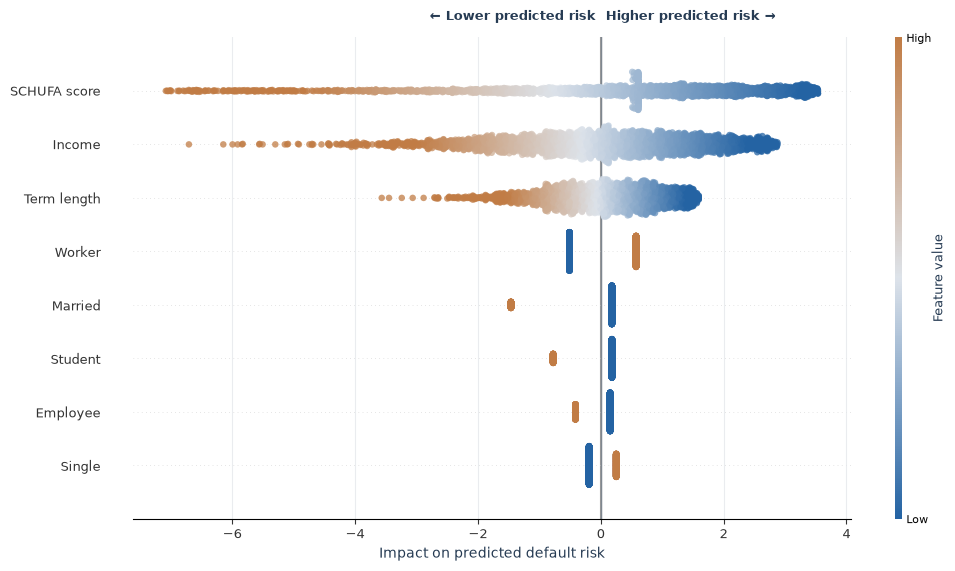

In [113]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

feature_labels = {
    "income": "Income",
    "loan_amount": "Loan amount",
    "term_length": "Term length",
    "install_to_inc": "Instalment / income",
    "schufa": "SCHUFA score",
    "num_applic_1": "One applicant",
    "num_applic_2": "Two applicants",
    "occup_code_1": "Occupation code 1",
    "occup_code_2": "Occupation code 2",
    "occup_code_3": "Occupation code 3",
    "occup_Employee": "Employee",
    "occup_Student": "Student",
    "occup_Worker": "Worker",
    "marital_Married": "Married",
    "marital_Single": "Single",
    "marital_Divorced": "Divorced",
    "marital_Separated": "Separated",
    "marital_Living together": "Living together"
}

display_names = [
    feature_labels.get(
        feature,
        feature.replace("_", " ").title()
    )
    for feature in feature_names
]

mean_absolute_shap = np.abs(
    shap_values.values
).mean(axis=0)

top_indices = np.argsort(
    mean_absolute_shap
)[-8:]

shap_for_plot = shap.Explanation(
    values=shap_values.values[:, top_indices],
    base_values=shap_values.base_values,
    data=np.asarray(shap_values.data)[:, top_indices],
    feature_names=[
        display_names[index]
        for index in top_indices
    ]
)

feature_value_colours = LinearSegmentedColormap.from_list(
    "feature_values",
    [
        "#2463A3",
        "#DDE3EA",
        "#C17C45"
    ]
)

shap.plots.beeswarm(
    shap_for_plot,
    max_display=8,
    color=feature_value_colours,
    show=False,
    plot_size=(10.5, 5.8),
    alpha=0.75,
    s=22
)

fig = plt.gcf()
ax = fig.axes[0]

ax.set_xlabel(
    "Impact on predicted default risk",
    fontsize=10,
    color="#263B53"
)

ax.axvline(
    0,
    color="#7F8790",
    linewidth=1
)

ax.xaxis.grid(
    True,
    color="#E5E8EC",
    linewidth=0.8,
    alpha=0.8
)

ax.set_axisbelow(True)
ax.tick_params(axis="both", labelsize=9)

ax.text(
    0,
    1.03,
    "← Lower predicted risk ",
    transform=ax.get_xaxis_transform(),
    ha="right",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color="#263B53"
)

ax.text(
    0,
    1.03,
    " Higher predicted risk →",
    transform=ax.get_xaxis_transform(),
    ha="left",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color="#263B53"
)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

if len(fig.axes) > 1:
    colour_bar = fig.axes[-1]
    colour_bar.set_ylabel(
        "Feature value",
        fontsize=9,
        color="#263B53"
    )
    colour_bar.tick_params(labelsize=8)

plt.tight_layout()

fig.savefig(
    "final_model_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

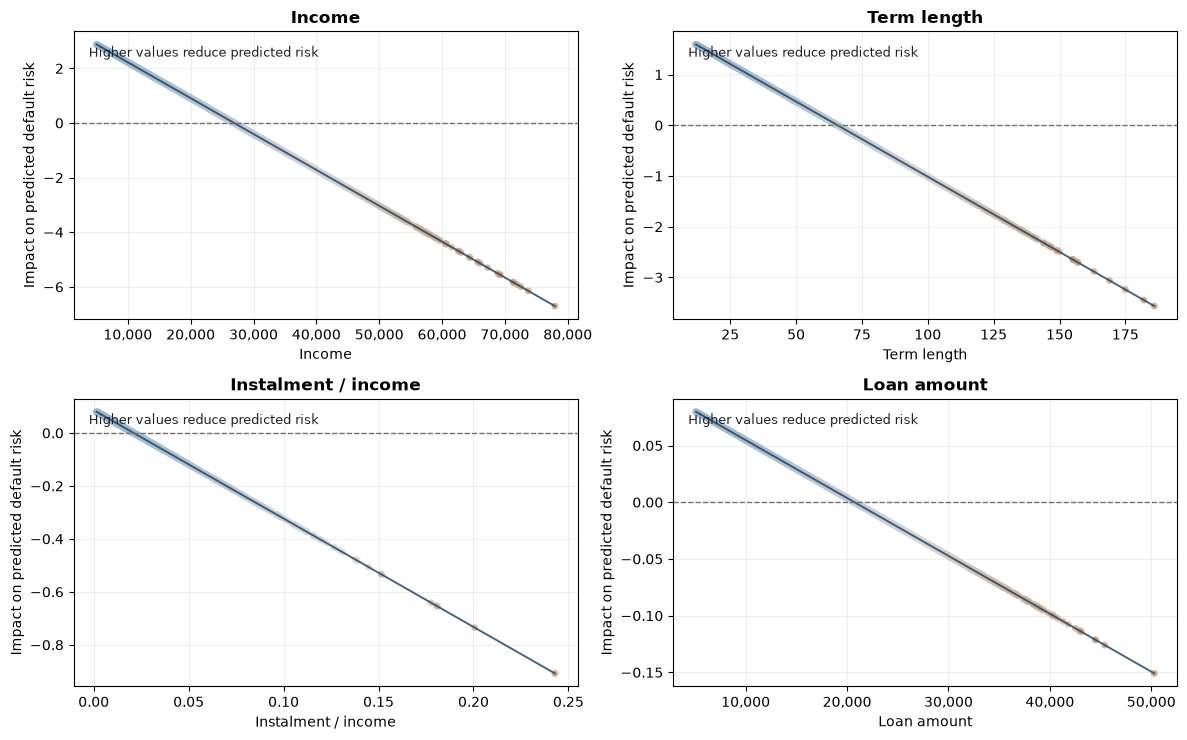

In [114]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

features_to_plot = {
    "income": "Income",
    "term_length": "Term length",
    "install_to_inc": "Instalment / income",
    "loan_amount": "Loan amount",
}

shap_feature_names = np.asarray(shap_values.feature_names)
shap_array = np.asarray(shap_values.values)

cmap = LinearSegmentedColormap.from_list(
    "ow_gradient",
    ["#9CB8CF", "#D8D8D8", "#C98245"]
)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
axes = axes.ravel()

for ax, (raw_feature, display_name) in zip(axes, features_to_plot.items()):
    matches = [
        i for i, name in enumerate(shap_feature_names)
        if name == raw_feature or name.endswith(f"__{raw_feature}")
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Could not uniquely identify {raw_feature!r}: "
            f"{shap_feature_names[matches].tolist()}"
        )

    x = pd.to_numeric(X_test[raw_feature], errors="coerce").to_numpy()
    y = shap_array[:, matches[0]]
    valid = np.isfinite(x) & np.isfinite(y)

    x_valid = x[valid]
    y_valid = y[valid]

    ax.scatter(
        x_valid,
        y_valid,
        c=x_valid,
        cmap=cmap,
        s=24,
        alpha=0.65,
        edgecolor="none"
    )

    order = np.argsort(x_valid)
    ax.plot(
        x_valid[order],
        y_valid[order],
        color="#173F64",
        linewidth=1.4,
        alpha=0.8
    )

    direction = (
        "Higher values increase predicted risk"
        if np.corrcoef(x_valid, y_valid)[0, 1] > 0
        else "Higher values reduce predicted risk"
    )

    ax.axhline(0, color="#707070", linewidth=1, linestyle="--")
    ax.set_title(display_name, fontsize=12, fontweight="bold")
    ax.set_xlabel(display_name)
    ax.set_ylabel("Impact on predicted default risk")
    ax.text(
        0.03, 0.95, direction,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color="#222222"
    )
    ax.grid(alpha=0.2)

    if raw_feature in {"income", "loan_amount"}:
        ax.xaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f"{value:,.0f}")
        )

plt.tight_layout()
plt.savefig(
    "numerical_feature_shap_plots.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)
plt.show()

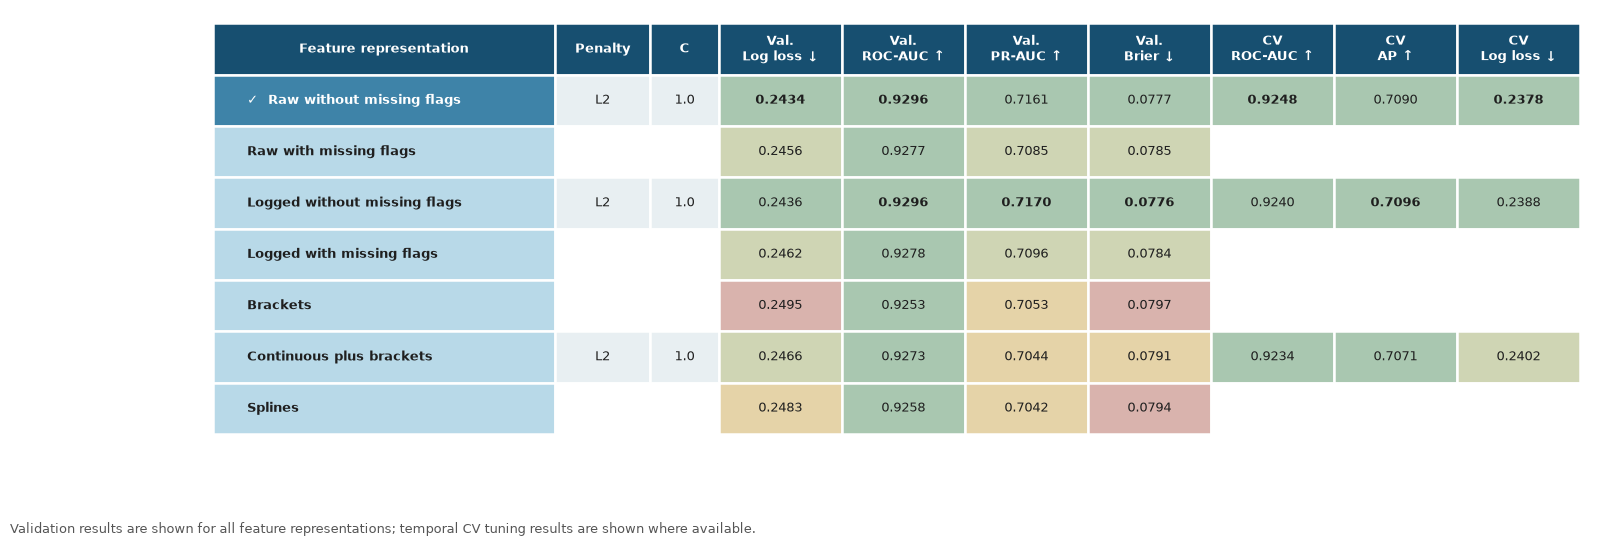

In [129]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

feature_order = [
    "Raw without missing flags",
    "Raw with missing flags",
    "Logged without missing flags",
    "Logged with missing flags",
    "Brackets",
    "Continuous plus brackets",
    "Splines"
]

selected_model = "Raw without missing flags"

results = all_validation_results.loc[
    feature_order,
    ["log_loss", "roc_auc", "pr_auc", "brier_score"]
].copy()

cv_details = pd.DataFrame(
    {
        "Raw without missing flags": {
            "Penalty": "L2",
            "C": 1.0,
            "CV ROC-AUC": 0.9248,
            "CV AP": 0.7090,
            "CV log loss": 0.2378
        },
        "Logged without missing flags": {
            "Penalty": "L2",
            "C": 1.0,
            "CV ROC-AUC": 0.9240,
            "CV AP": 0.7096,
            "CV log loss": 0.2388
        },
        "Continuous plus brackets": {
            "Penalty": "L2",
            "C": 1.0,
            "CV ROC-AUC": 0.9234,
            "CV AP": 0.7071,
            "CV log loss": 0.2402
        }
    }
).T

table_data = pd.DataFrame(index=feature_order)

table_data["Penalty"] = cv_details["Penalty"]
table_data["C"] = cv_details["C"]

table_data["Val. log loss"] = results["log_loss"]
table_data["Val. ROC-AUC"] = results["roc_auc"]
table_data["Val. PR-AUC"] = results["pr_auc"]
table_data["Val. Brier"] = results["brier_score"]

table_data["CV ROC-AUC"] = cv_details["CV ROC-AUC"]
table_data["CV AP"] = cv_details["CV AP"]
table_data["CV log loss"] = cv_details["CV log loss"]

metric_directions = {
    "Val. log loss": False,
    "Val. ROC-AUC": True,
    "Val. PR-AUC": True,
    "Val. Brier": False,
    "CV ROC-AUC": True,
    "CV AP": True,
    "CV log loss": False
}

def performance_colour(value, best, higher_is_better):
    if higher_is_better:
        percentage_gap = (best - value) / abs(best)
    else:
        percentage_gap = (value - best) / abs(best)

    if percentage_gap <= 0.005:
        return "#A9C7B0"
    if percentage_gap <= 0.015:
        return "#CFD5B4"
    if percentage_gap <= 0.0225:
        return "#E5D3A8"
    return "#D9B3AD"

headers = [
    "Feature representation",
    "Penalty",
    "C",
    "Val.\nLog loss ↓",
    "Val.\nROC-AUC ↑",
    "Val.\nPR-AUC ↑",
    "Val.\nBrier ↓",
    "CV\nROC-AUC ↑",
    "CV\nAP ↑",
    "CV\nLog loss ↓"
]

cell_text = []

for model in feature_order:
    label = f"✓  {model}" if model == selected_model else model
    row = [label]

    for column in table_data.columns:
        value = table_data.loc[model, column]

        if pd.isna(value):
            row.append("")
        elif column == "Penalty":
            row.append(str(value))
        elif column == "C":
            row.append(f"{float(value):.1f}")
        else:
            row.append(f"{float(value):.4f}")

    cell_text.append(row)

fig, ax = plt.subplots(figsize=(18, 6.2))
ax.axis("off")

table = ax.table(
    cellText=cell_text,
    colLabels=headers,
    cellLoc="center",
    colLoc="center",
    loc="center",
    bbox=[0.01, 0.11, 0.98, 0.86]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

navy = "#174F70"
selected_blue = "#3E83A8"
label_blue = "#B8D9E8"
parameter_fill = "#E8EFF2"
white = "#FFFFFF"

for column in range(len(headers)):
    cell = table[(0, column)]
    cell.set_facecolor(navy)
    cell.set_text_props(color=white, weight="bold")
    cell.set_edgecolor(white)
    cell.set_linewidth(1.8)

for row, model in enumerate(feature_order, start=1):
    name_cell = table[(row, 0)]
    name_cell.set_facecolor(
        selected_blue if model == selected_model else label_blue
    )
    name_cell.set_text_props(
        color=white if model == selected_model else "#1F1F1F",
        weight="bold"
    )
    name_cell.get_text().set_ha("left")
    name_cell.set_edgecolor(white)
    name_cell.set_linewidth(1.8)

    for column_position, column_name in enumerate(
        table_data.columns,
        start=1
    ):
        value = table_data.loc[model, column_name]
        cell = table[(row, column_position)]

        cell.set_edgecolor(white)
        cell.set_linewidth(1.8)

        if pd.isna(value):
            cell.set_facecolor(white)
            continue

        if column_name in {"Penalty", "C"}:
            cell.set_facecolor(parameter_fill)
            cell.set_text_props(color="#1F1F1F")
            continue

        metric_values = pd.to_numeric(
            table_data[column_name],
            errors="coerce"
        ).dropna()

        higher_is_better = metric_directions[column_name]
        best = (
            metric_values.max()
            if higher_is_better
            else metric_values.min()
        )

        cell.set_facecolor(
            performance_colour(
                float(value),
                float(best),
                higher_is_better
            )
        )

        cell.set_text_props(
            color="#1F1F1F",
            weight="bold"
            if np.isclose(float(value), float(best), atol=5e-5)
            else "normal"
        )

column_widths = [
    0.25, 0.07, 0.05,
    0.09, 0.09, 0.09, 0.09,
    0.09, 0.09, 0.09
]

for (row, column), cell in table.get_celld().items():
    cell.set_width(column_widths[column])
    cell.set_height(0.115)

fig.text(
    0.02,
    0.035,
    "Validation results are shown for all feature representations; "
    "temporal CV tuning results are shown where available.",
    fontsize=9,
    color="#555555"
)

plt.savefig(
    "feature_screening_and_cv_table.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

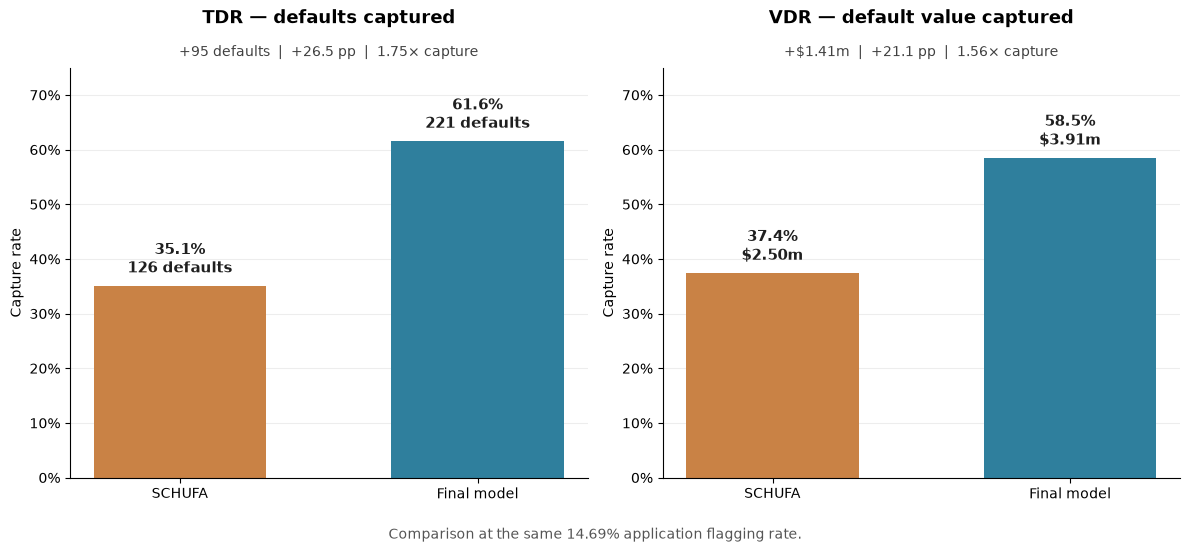

In [130]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

currency_symbol = "$"

labels = ["SCHUFA", "Final model"]
colours = ["#C98245", "#2F7F9D"]

tdr_pct = [35.10, 61.56]
tdr_count = [126, 221]

vdr_pct = [37.41, 58.49]
vdr_value = [2_503_200, 3_914_100]

def format_money(value):
    if abs(value) >= 1_000_000:
        return f"{currency_symbol}{value / 1_000_000:.2f}m"
    if abs(value) >= 1_000:
        return f"{currency_symbol}{value / 1_000:.0f}k"
    return f"{currency_symbol}{value:,.0f}"

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

charts = [
    {
        "ax": axes[0],
        "values": tdr_pct,
        "title": "TDR — defaults captured",
        "annotations": [
            f"{tdr_pct[0]:.1f}%\n{tdr_count[0]:,} defaults",
            f"{tdr_pct[1]:.1f}%\n{tdr_count[1]:,} defaults"
        ],
        "summary": (
            f"+{tdr_count[1] - tdr_count[0]:,} defaults  |  "
            f"+{tdr_pct[1] - tdr_pct[0]:.1f} pp  |  "
            f"{tdr_pct[1] / tdr_pct[0]:.2f}× capture"
        )
    },
    {
        "ax": axes[1],
        "values": vdr_pct,
        "title": "VDR — default value captured",
        "annotations": [
            f"{vdr_pct[0]:.1f}%\n{format_money(vdr_value[0])}",
            f"{vdr_pct[1]:.1f}%\n{format_money(vdr_value[1])}"
        ],
        "summary": (
            f"+{format_money(vdr_value[1] - vdr_value[0])}  |  "
            f"+{vdr_pct[1] - vdr_pct[0]:.1f} pp  |  "
            f"{vdr_pct[1] / vdr_pct[0]:.2f}× capture"
        )
    }
]

for chart in charts:
    ax = chart["ax"]

    bars = ax.bar(
        labels,
        chart["values"],
        color=colours,
        width=0.58
    )

    ax.set_title(
        chart["title"],
        fontsize=13,
        fontweight="bold",
        pad=32
    )

    ax.text(
        0.5,
        1.02,
        chart["summary"],
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="#404040"
    )

    for bar, annotation in zip(bars, chart["annotations"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.5,
            annotation,
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="#1F1F1F"
        )

    ax.set_ylim(0, 75)
    ax.set_ylabel("Capture rate")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.text(
    0.5,
    0.01,
    "Comparison at the same 14.69% application flagging rate.",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "tdr_vdr_improvement.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()